# Teaching a Neural Network the Boundary Layer on a Flat Plate
### A third-order ODE (the Blasius equation) with a Physics-Informed Neural Network: NumPy from scratch (Part A) and PyTorch (Part B)

**Author:** Dishanand Jayeprokash

Air flowing over an aircraft wing does not slide past the surface freely. The layer of air that touches the metal is held still by friction, and the layers above it are slowed down a little less, and so on, until a thin region next to the surface has gone from "stopped" to "full speed". That thin region is the **boundary layer**. It decides how much drag a wing has, how hot a re-entry vehicle gets, and how a turbine blade performs.

For the simplest case, steady air flowing over a flat plate, the whole boundary layer collapses into one ordinary differential equation, first written down by Heinrich Blasius in 1908:

$$
f''' + \tfrac12\, f\, f'' = 0 .
$$

It looks short. It has no closed-form solution, so engineers have been solving it numerically for over a century. In this notebook a neural network learns the solution **using nothing but the equation and three boundary conditions**. No measurements are needed.


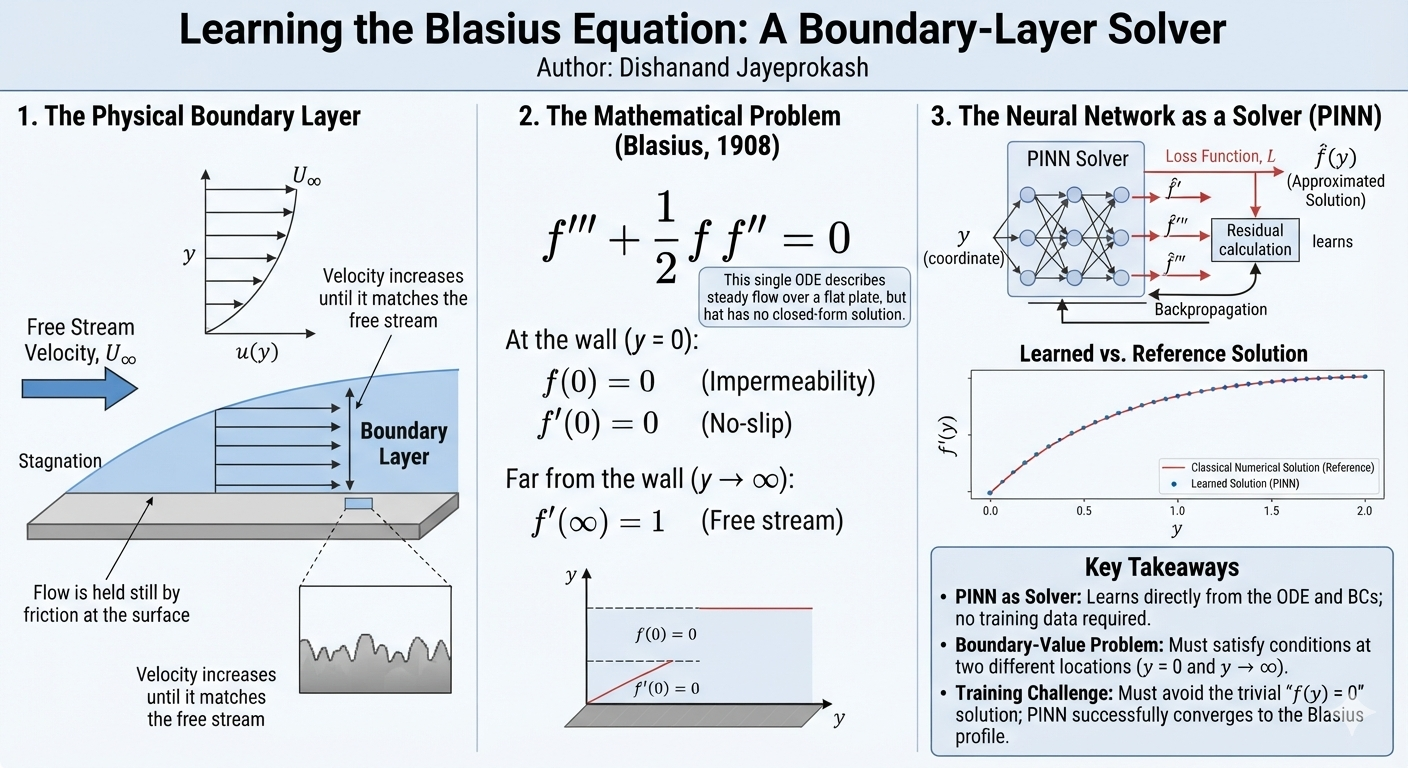

Here we go to **third order**, and three things are new:

* **There are no data.** The network is a *solver*, not a curve fit. We judge it against a reference solution computed in a classical way.
* **The conditions sit in two places.** Two are at the wall and one is far from it, so this is a *boundary-value* problem, not an initial-value problem like the first two notebooks.
* **Training can get stuck.** The equation has a useless "do nothing" solution, and a network started from random weights can fall into it. We show this happening, explain why, and fix it.

**What you will find here**

| Section | What it covers |
|---|---|
| **Background** | Where the boundary layer comes from, a full derivation of the Blasius equation from the flow equations, the quantities engineers read off the solution (skin friction, layer thickness, drag), and how the PINN loss is built for a third-order equation |
| **Setup** | Constants, a reference solver, an interactive boundary-layer explorer, and the plotting and video helpers used by both parts |
| **Part A** | Everything by hand in NumPy: a network that returns three derivatives of itself, hand-derived gradients, a gradient check, Adam, a survey of random starts, the warm-start fix, a side-by-side training video and GIF, and an inverse problem where noisy velocity readings give the wall friction |
| **Part B** | The same in PyTorch with automatic differentiation, then L-BFGS, `torch.func`, an inverse problem with a trainable constant, and wedge flows (Falkner–Skan) |

**Requirements:** Python 3.9+, `numpy`, `scipy`, `matplotlib`, `pillow`. Optional: `ipywidgets` (sliders), `ffmpeg` (MP4 files), `torch` (Part B).

---
# Background

## 1. Why the layer near a surface matters

Take a flat plate, thin enough that it barely disturbs the flow, lined up with a steady stream of air at speed $U$. Air that touches the plate sticks to it (the **no-slip** condition), so its speed there is zero. Far from the plate the air still moves at $U$. Somewhere in between, the speed has to climb from 0 to $U$.

Ludwig Prandtl realised in 1904 that for fast flows of thin fluids like air or water, this climb happens in a very thin layer. Outside it, friction hardly matters. Inside it, friction is everything. That insight split a very hard problem into two easier ones and is the basis of modern aerodynamics.

How thin is thin? For air ($\nu\approx1.5\times10^{-5}$ m²/s) moving at 10 m/s, half a metre from the front edge of a plate, the layer is only about **4 millimetres** thick. We will compute that number ourselves in the Setup section.

## 2. The flow equations

We look at steady, two-dimensional flow of an incompressible fluid (constant density $\rho$, kinematic viscosity $\nu$). Let $x$ run along the plate from its front edge and $y$ run away from the surface. The velocity has two parts: $u$ along the plate and $v$ away from it.

**Mass conservation** (what flows in must flow out):
$$
\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}=0 .
$$

**Momentum** (the Navier–Stokes equation for the $x$ direction):
$$
u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y}=-\frac1\rho\frac{\partial p}{\partial x}+\nu\left(\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\right).
$$
The left side is the fluid carrying its own momentum along. The right side is pressure pushing and viscosity smearing momentum between neighbouring layers.

## 3. Using the fact that the layer is thin

Prandtl's simplification rests on one observation: the boundary layer is far thinner than the plate is long, $\delta\ll x$. Three things follow.

1. Velocity changes much faster across the layer than along it, so $\partial^2u/\partial x^2\ll\partial^2u/\partial y^2$. We drop the first.
2. The pressure does not change across such a thin layer, so the pressure inside equals the pressure just outside.
3. Outside the layer the flow is a uniform stream, so (by Bernoulli's law) its pressure does not change along $x$ either. Therefore $\partial p/\partial x=0$.

The momentum equation becomes the **boundary-layer equation**:
$$
u\frac{\partial u}{\partial x}+v\frac{\partial u}{\partial y}=\nu\,\frac{\partial^2u}{\partial y^2}.
\tag{1}
$$

**How thick is the layer? A scaling argument.** Suppose the layer has thickness $\delta$ at a distance $x$ from the front. Then $u\sim U$, $\partial u/\partial x\sim U/x$ and $\partial^2u/\partial y^2\sim U/\delta^2$. Mass conservation gives $v\sim U\delta/x$. In equation (1), the inertia terms are both about $U^2/x$ and the friction term is about $\nu U/\delta^2$. If friction is the thing that shapes the layer, these two must be of the same size:
$$
\frac{U^2}{x}\sim\frac{\nu U}{\delta^2}
\quad\Longrightarrow\quad
\delta\sim\sqrt{\frac{\nu x}{U}} .
$$
So the layer grows like the **square root of the distance** from the front. This hint is the key to the next step.

## 4. Turning the problem into one ODE: the similarity solution

Equation (1) has two unknown functions, $u(x,y)$ and $v(x,y)$, and two variables. The scaling argument suggests that the velocity profile looks the same at every $x$ if we measure $y$ in units of $\delta(x)$. We use that idea and see whether the equation lets us get away with a single variable.

**Step 1: a stream function.** Mass conservation holds automatically if we write the velocities as derivatives of one function $\psi(x,y)$:
$$
u=\frac{\partial\psi}{\partial y},\qquad v=-\frac{\partial\psi}{\partial x}.
$$
(Check: $u_x+v_y=\psi_{yx}-\psi_{xy}=0$.) Equation (1) becomes
$$
\psi_y\,\psi_{xy}-\psi_x\,\psi_{yy}=\nu\,\psi_{yyy}.
$$

**Step 2: the similarity variable.** Following the scaling $\delta\sim\sqrt{\nu x/U}$, define
$$
\eta=y\sqrt{\frac{U}{\nu x}} ,\qquad
\psi(x,y)=\sqrt{\nu x U}\;f(\eta).
$$
The number $\eta$ is "how many boundary-layer thicknesses away from the plate are we". The unknown is now one function $f$ of one variable.

**Step 3: work out each piece.** We need the chain rule, using $\partial\eta/\partial y=\sqrt{U/(\nu x)}$ and $\partial\eta/\partial x=-\dfrac{\eta}{2x}$.

*Velocity along the plate:*
$$
u=\frac{\partial\psi}{\partial y}=\sqrt{\nu xU}\,f'(\eta)\sqrt{\frac{U}{\nu x}}=U\,f'(\eta).
$$
So **$f'(\eta)$ is the velocity as a fraction of the free-stream speed**, $u/U$. This is the quantity people plot and measure.

*Velocity away from the plate:*
$$
v=-\frac{\partial\psi}{\partial x}=-\left[\tfrac12\sqrt{\tfrac{\nu U}{x}}\,f+\sqrt{\nu xU}\,f'\left(-\tfrac{\eta}{2x}\right)\right]=\tfrac12\sqrt{\tfrac{\nu U}{x}}\,\big(\eta f'-f\big).
$$

*Derivatives of $u$:*
$$
\frac{\partial u}{\partial x}=U f''\left(-\frac{\eta}{2x}\right)=-\frac{U\eta}{2x}f'',\qquad
\frac{\partial u}{\partial y}=U f''\sqrt{\frac{U}{\nu x}},\qquad
\frac{\partial^2u}{\partial y^2}=\frac{U^2}{\nu x}\,f''' .
$$

**Step 4: put them into equation (1).** The left side is
$$
u\,u_x+v\,u_y=Uf'\left(-\frac{U\eta}{2x}f''\right)+\tfrac12\sqrt{\tfrac{\nu U}{x}}(\eta f'-f)\,Uf''\sqrt{\tfrac{U}{\nu x}}
=-\frac{U^2\eta}{2x}f'f''+\frac{U^2}{2x}(\eta f'-f)f'' .
$$
The two terms with $\eta f'f''$ cancel and what is left is $-\dfrac{U^2}{2x}\,f\,f''$. The right side is $\nu u_{yy}=\dfrac{U^2}{x}f'''$. Setting them equal and cancelling $U^2/x$:
$$
\boxed{\,f'''+\tfrac12\,f\,f''=0\,}
\tag{2}
$$
All the dependence on $x$, $U$ and $\nu$ has dropped out. **One equation describes every flat-plate boundary layer, at every speed, in every fluid and at every distance.** That is the real power of the similarity solution. We solve it once, and then rescale.

## 5. The boundary conditions

Equation (2) is third-order, so it needs three conditions. They come from the physics:

| Condition | Meaning |
|---|---|
| $f(0)=0$ | the wall is solid, so no air flows through it ($v=0$ at $\eta=0$, which from the formula for $v$ means $f(0)=0$ given $f'(0)=0$) |
| $f'(0)=0$ | no-slip: the air touching the wall is at rest ($u=0$) |
| $f'(\infty)=1$ | far from the wall the air moves at the free-stream speed ($u=U$) |

**This is not like the first two notebooks.** There, every condition was given at the starting time $t=0$, and we could march forward in time. Here two conditions are at the wall and one is at $\eta=\infty$. You cannot just start at the wall and integrate outwards, because you do not know the third starting value, $f''(0)$. It is a **boundary-value problem**.

In practice we replace "infinity" by a large but finite value $\eta_{\max}$. The profile is already within one part in a hundred thousand of the free stream by $\eta\approx8$, so we use $\eta_{\max}=8$.

## 6. Computing a reference answer: a rescaling trick

To judge the neural network we need a trustworthy answer from a classical method. There is a neat way to get one without any trial-and-error.

**The scaling property.** Suppose $f(\eta)$ solves $f'''+\tfrac12ff''=0$, and define a stretched copy $g(\eta)=\lambda f(\lambda\eta)$ for any number $\lambda>0$. Then $g'''=\lambda^4f'''$ and $g\,g''=\lambda f\cdot\lambda^3f''=\lambda^4ff''$, so $g$ solves the same equation. What changes are the conditions: $g'(\infty)=\lambda^2f'(\infty)$ and $g''(0)=\lambda^3f''(0)$.

**The plan.**

1. Solve the equation as an ordinary initial-value problem starting with $f(0)=0$, $f'(0)=0$ and the easy guess $f''(0)=1$. Call the result $f_1$ and let $A=f_1'(\infty)$ be its far-field speed. (It comes out near 2.085, not 1.)
2. Choose $\lambda$ so that $\lambda^2A=1$, i.e. $\lambda=A^{-1/2}$. Then $g=\lambda f_1(\lambda\eta)$ has the right far-field speed.
3. Its wall slope is $g''(0)=\lambda^3\cdot 1=A^{-3/2}$.

This gives the famous number $f''(0)=A^{-3/2}\approx0.3321$ from a single run of a standard integrator. We will check it in the Setup section.

## 7. What engineers read off the solution

Once we have $f$, everything useful follows. Let $\mathrm{Re}_x=Ux/\nu$ be the Reynolds number at distance $x$.

**Wall shear and skin friction.** The friction force per area on the plate is $\tau_w=\mu\,(\partial u/\partial y)_{y=0}$ with $\mu=\rho\nu$. From the formulas in section 4, $(\partial u/\partial y)_{y=0}=U f''(0)\sqrt{U/(\nu x)}$, so
$$
\tau_w=\mu U f''(0)\sqrt{\frac{U}{\nu x}},\qquad
c_f=\frac{\tau_w}{\tfrac12\rho U^2}=\frac{2f''(0)}{\sqrt{\mathrm{Re}_x}}\approx\frac{0.664}{\sqrt{\mathrm{Re}_x}}.
$$
So **$f''(0)$ sets the drag**. A wall-slope error of 1% is a drag error of 1%.

**Layer thickness.** By convention $\delta_{99}$ is the height where $u=0.99U$. In similarity terms, find $\eta_{99}$ with $f'(\eta_{99})=0.99$, then $\delta_{99}=\eta_{99}\sqrt{\nu x/U}$. The answer is $\eta_{99}\approx4.91$.

**Displacement thickness.** The slowed-down air pushes the outer flow away from the wall by the distance
$$
\delta^*=\int_0^\infty\Big(1-\frac uU\Big)dy=\sqrt{\frac{\nu x}{U}}\int_0^\infty(1-f')\,d\eta\approx1.721\sqrt{\frac{\nu x}{U}} .
$$

**Momentum thickness.**
$$
\theta=\int_0^\infty\frac uU\Big(1-\frac uU\Big)dy=\sqrt{\frac{\nu x}{U}}\int_0^\infty f'(1-f')\,d\eta\approx0.664\sqrt{\frac{\nu x}{U}} .
$$

**Drag on a plate of length $L$.** Averaging $c_f$ over the length,
$$
C_D=\frac1L\int_0^L c_f\,dx=\frac{0.664}{\sqrt{U/\nu}}\cdot\frac{2\sqrt L}{L}=\frac{1.328}{\sqrt{\mathrm{Re}_L}} .
$$

**A built-in physics check.** The momentum thickness and the wall shear are linked by the von Kármán momentum balance, $\dfrac{\tau_w}{\rho U^2}=\dfrac{d\theta}{dx}$. Insert $\theta=I\sqrt{\nu x/U}$ with $I=\int f'(1-f')d\eta$: the left side is $f''(0)\sqrt{\nu/(Ux)}$ and the right side is $\tfrac I2\sqrt{\nu/(Ux)}$. Therefore
$$
\boxed{\,\int_0^\infty f'(1-f')\,d\eta=2\,f''(0)\,}
\tag{3}
$$
Any correct solution must obey (3). We can test a network against it **without knowing the exact answer**, just like the energy check in the oscillator notebook.

## 8. Where the model stops being valid
* **Laminar flow only.** On a smooth plate the flow stays smooth up to roughly $\mathrm{Re}_x\approx5\times10^5$ and then turns turbulent. The Blasius solution says nothing beyond that.
* **Zero pressure gradient.** A real wing has a pressure that changes along the surface. Section B12 in Part B treats that case (Falkner–Skan flows).
* **Not at the very front.** Close to the leading edge the layer is not thin compared with $x$, and the thin-layer assumption fails.

## 9. The PINN for a third-order equation

The network $\hat f_\theta(\eta)$ takes $\eta\in[0,\eta_{\max}]$ and returns a value for $f$. Because the network is built from smooth functions, we can differentiate it **three times**. The loss has two parts.

**Equation loss.** Pick $N_c$ points $\eta_j$ spread over $[0,\eta_{\max}]$ (collocation points, as before). At each, form the residual of equation (2):
$$
r(\eta_j)=\hat f'''(\eta_j)+\tfrac12\,\hat f(\eta_j)\,\hat f''(\eta_j),\qquad
\mathcal L_{\text{ODE}}=\frac1{N_c}\sum_j r(\eta_j)^2 .
$$

**Boundary loss.** Three conditions, three squared errors:
$$
\mathcal L_{\text{BC}}=\hat f(0)^2+\hat f'(0)^2+\big(\hat f'(\eta_{\max})-1\big)^2 .
$$

**Total loss:** $\mathcal L=\lambda_{\text{ODE}}\mathcal L_{\text{ODE}}+\lambda_{\text{BC}}\mathcal L_{\text{BC}}$.

There is no data term, because there are no measurements. We add one in the inverse problem later.

## 10. Differentiating the network three times

We use the same layer-by-layer approach as in the oscillator notebook, now carrying a third derivative. For a hidden layer with input values $(\mathbf P,\dot{\mathbf P},\ddot{\mathbf P},\dddot{\mathbf P})$ (a dot means $d/d\eta$):

* **Linear step.** $\mathbf Z=\mathbf P\mathbf W+\mathbf b$, and each derivative passes straight through: $\dot{\mathbf Z}=\dot{\mathbf P}\mathbf W$, $\ddot{\mathbf Z}=\ddot{\mathbf P}\mathbf W$, $\dddot{\mathbf Z}=\dddot{\mathbf P}\mathbf W$.
* **Activation step.** With $\mathbf A=\tanh\mathbf Z$ and $\mathbf S=1-\mathbf A^2$. The first two derivatives are as before:
$$
\dot{\mathbf A}=\mathbf S\dot{\mathbf Z},\qquad
\ddot{\mathbf A}=\mathbf S\ddot{\mathbf Z}-2\mathbf A\mathbf S\dot{\mathbf Z}^{2}.
$$
For the third, differentiate $\ddot{\mathbf A}$ once more. Use $\dot{\mathbf S}=-2\mathbf A\mathbf S\dot{\mathbf Z}$ and $\dot{\mathbf A}=\mathbf S\dot{\mathbf Z}$:

$$
\begin{aligned}
\frac{d}{d\eta}\big(\mathbf S\ddot{\mathbf Z}\big)&=-2\mathbf A\mathbf S\dot{\mathbf Z}\ddot{\mathbf Z}+\mathbf S\dddot{\mathbf Z},\\
\frac{d}{d\eta}\big(-2\mathbf A\mathbf S\dot{\mathbf Z}^{2}\big)&=-2\mathbf S^{2}\dot{\mathbf Z}^{3}+4\mathbf A^{2}\mathbf S\dot{\mathbf Z}^{3}-4\mathbf A\mathbf S\dot{\mathbf Z}\ddot{\mathbf Z}.
\end{aligned}
$$
Adding them and tidying up (using $4\mathbf A^2\mathbf S-2\mathbf S^2=-2\mathbf S(1-3\mathbf A^2)$):
$$
\dddot{\mathbf A}=\mathbf S\,\dddot{\mathbf Z}-6\,\mathbf A\,\mathbf S\,\dot{\mathbf Z}\ddot{\mathbf Z}-2\,\mathbf S\,(1-3\mathbf A^2)\,\dot{\mathbf Z}^{3}.
$$
As a sanity check, for a plain $\tanh$ of $\eta$ itself ($\dot Z=1$, $\ddot Z=\dddot Z=0$) this gives $\tanh'''=-2(1-\tanh^2)(1-3\tanh^2)$, which is the textbook result.
* **Start of the chain.** The input is $\eta$, so $\dot{\mathbf P}_0=1$ and $\ddot{\mathbf P}_0=\dddot{\mathbf P}_0=0$.

## 11. Things that can go wrong: a trap near the "do nothing" solution

Look at equation (2) and the wall conditions. The function $f\equiv0$ satisfies $f'''+\tfrac12ff''=0$ (every term is zero), and also $f(0)=0$ and $f'(0)=0$. The only condition it breaks is $f'(\eta_{\max})=1$, which is a single point out of the many the loss looks at.

So a network started from random weights can end up in a different, wrong state: a smooth profile that dips below zero and then climbs to 1 at the far edge, with $f$ staying small and negative (about $-0.27$ at $\eta_{\max}$, where the true value is about 6.3). This state meets all three boundary conditions almost perfectly, but it does not obey the equation, and it is hard to leave. The loss sits near $2\times10^{-3}$, thousands of times higher than in a successful run. The same state (wall slope about $-0.13$) showed up for different seeds, network widths and training lengths in our tests, which points to one specific local minimum. It is a real hazard of PINNs, not a bug in the code, and it depends on the random starting weights. It may be no coincidence that $f\equiv0$ solves the equation and both wall conditions, so small $f$ is close to a solution everywhere except at the far edge, but we did not prove that link.

We will measure how often this happens in Part A. The remedy we use is a short **warm-up**: before turning the physics on, we briefly train the network to match a rough, physically sensible guess for the velocity profile, namely a curve that rises from 0 at the wall towards 1 far away. The guess does not have to be accurate. It only has to start the network away from $f=0$.

## 12. The inverse problem: finding the wall friction from noisy readings

Now suppose we have real measurements. A hot-wire probe or a laser system (particle image velocimetry) records the velocity $u(y_i)$ at several heights above the plate at a fixed station $x$. Two practical problems arise:

* The readings are noisy.
* Nobody can measure very close to the wall. The probe or the laser spot has a finite size.

Yet the quantity we most want is exactly at the wall, the slope $(\partial u/\partial y)_{y=0}$, because it gives the drag.

We also may not know the length scale of the layer, i.e. $\kappa=\sqrt{U/(\nu x)}$, which links the physical height to the similarity variable: $\eta=\kappa\,y$ and $u/U=f'(\kappa y)$. So we treat $\kappa$ as an unknown and train the network and $\kappa$ together on
$$
\mathcal L=\lambda_{\text{ODE}}\mathcal L_{\text{ODE}}+\lambda_{\text{BC}}\mathcal L_{\text{BC}}+\lambda_{\text{data}}\,\frac1{N_d}\sum_i\Big(\hat f'(\kappa y_i)-\frac{u_i}{U}\Big)^2 .
$$
The physics fills in the part we cannot measure. The extra gradient we need comes from the chain rule: since $\partial\hat f'(\kappa y_i)/\partial\kappa=y_i\,\hat f''(\kappa y_i)$,
$$
\frac{\partial\mathcal L_{\text{data}}}{\partial\kappa}=\frac2{N_d}\sum_i r_i\,y_i\,\hat f''(\kappa y_i),\qquad r_i=\hat f'(\kappa y_i)-\frac{u_i}{U}.
$$
The wall slope is then $\partial u/\partial y|_0=U\kappa\hat f''(0)$, and $\delta_{99}=\eta_{99}/\kappa$.

---
# Setup (shared by both parts)

The cells in this section define the constants, the reference solution, an interactive explorer, and the helper functions for plotting and for making the training video. Only NumPy, SciPy and Matplotlib are used. Run them once, then go to Part A or Part B.

## S1. Imports

In [1]:
import os
import time
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.integrate import solve_ivp

# a folder for the video and the GIF
MEDIA_DIR = Path("media")
MEDIA_DIR.mkdir(exist_ok=True)

## S2. Constants
`ETA_MAX` is our stand-in for "infinity" (section 5). The flow numbers describe a realistic case: air at 10 m/s over a plate 1 m long. We will use them to turn the dimensionless solution into millimetres and seconds.

In [2]:
ETA_MAX = 8.0            # the far edge of the computational domain (stands in for infinity)

# a realistic flat-plate case
U_inf = 10.0             # free-stream speed (m/s)
nu_air = 1.5e-5          # kinematic viscosity of air (m^2/s)
rho_air = 1.2            # density of air (kg/m^3)
plate_length = 1.0       # length of the plate (m)
x_station = 0.5          # where we take measurements (m from the front edge)

## S3. The reference solution (the rescaling trick of section 6)
One run of a standard integrator (`solve_ivp`, an eighth-order Runge–Kutta method) with $f''(0)=1$, then the rescaling $g(\eta)=\lambda f_1(\lambda\eta)$ with $\lambda=A^{-1/2}$. The function returns another function `ref(eta)` that gives $f$, $f'$ and $f''$ at any $\eta$, plus the wall slope $A^{-3/2}$.

In [3]:
def blasius_reference(eta_stop=40.0):
    # solve f''' + 0.5 f f'' = 0 starting from f''(0) = 1, then rescale so that f'(infinity) = 1.
    sol = solve_ivp(lambda e, y: [y[1], y[2], -0.5 * y[0] * y[2]],
                    [0.0, eta_stop], [0.0, 0.0, 1.0],
                    method="DOP853", rtol=1e-12, atol=1e-14, dense_output=True)
    A = sol.y[1, -1]                    # far-field speed of the unscaled solution
    lam = A ** -0.5                     # stretch factor
    wall_slope = A ** -1.5              # f''(0) of the rescaled solution

    def ref(eta):
        x = np.asarray(eta, dtype=float)
        y = sol.sol(lam * x.ravel())
        f = (lam * y[0]).reshape(x.shape)
        f1 = (lam**2 * y[1]).reshape(x.shape)
        f2 = (lam**3 * y[2]).reshape(x.shape)
        return f, f1, f2
    return ref, wall_slope, A


ref, wall_slope_exact, A_unscaled = blasius_reference()
print(f"far-field speed of the unscaled run  A = {A_unscaled:.6f}")
print(f"wall slope  f''(0) = A^(-3/2)        = {wall_slope_exact:.6f}   (textbook value: about 0.3321)")
print(f"velocity at the edge of our domain   f'({ETA_MAX:.0f}) = {ref(ETA_MAX)[1]:.7f}   (should be very close to 1)")

# fine grid and exact curves used for plotting and for errors
eta_grid = np.linspace(0.0, ETA_MAX, 400).reshape(-1, 1)
f_exact, f1_exact, f2_exact = ref(eta_grid)

far-field speed of the unscaled run  A = 2.085409
wall slope  f''(0) = A^(-3/2)        = 0.332057   (textbook value: about 0.3321)
velocity at the edge of our domain   f'(8) = 0.9999963   (should be very close to 1)


## S4. Numbers an engineer cares about
This helper turns any profile $f'(\eta)$ into the quantities of section 7: the layer thickness $\eta_{99}$, the displacement integral $\int(1-f')d\eta$, the momentum integral $\int f'(1-f')d\eta$, and the two sides of the momentum check (3). It uses the trapezoid rule on the grid. We apply it to the reference solution now and to the networks later.

In [4]:
def trapezoid(y, x):
    y, x = np.asarray(y).ravel(), np.asarray(x).ravel()
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))


def boundary_layer_numbers(eta, f1, wall_slope):
    # eta, f1: profile on a grid; wall_slope: f''(0)
    eta, f1 = np.asarray(eta).ravel(), np.asarray(f1).ravel()
    above = np.where(f1 >= 0.99)[0]
    if len(above) == 0 or above[0] == 0:
        eta99 = float("nan")                    # the profile never reaches 0.99 (a failed solution)
    else:
        i = above[0]                            # linear interpolation between the two grid points
        eta99 = eta[i - 1] + (0.99 - f1[i - 1]) * (eta[i] - eta[i - 1]) / (f1[i] - f1[i - 1])
    return {
        "wall slope f''(0)": float(wall_slope),
        "eta_99": float(eta99),
        "displacement integral": trapezoid(1.0 - f1, eta),
        "momentum integral": trapezoid(f1 * (1.0 - f1), eta),
        "2 f''(0)  (momentum check)": 2.0 * float(wall_slope),
    }


ref_numbers = boundary_layer_numbers(eta_grid, f1_exact, wall_slope_exact)
textbook = {"wall slope f''(0)": 0.3321, "eta_99": 4.91, "displacement integral": 1.721,
            "momentum integral": 0.664, "2 f''(0)  (momentum check)": 0.664}
print(f"{'quantity':32s}{'reference solution':>20s}{'textbook':>12s}")
for key, value in ref_numbers.items():
    print(f"{key:32s}{value:20.4f}{textbook[key]:12.3f}")

quantity                          reference solution    textbook
wall slope f''(0)                             0.3321       0.332
eta_99                                        4.9100       4.910
displacement integral                         1.7208       1.721
momentum integral                             0.6641       0.664
2 f''(0)  (momentum check)                    0.6641       0.664


The reference solution reproduces the textbook values, and the momentum check (3) holds: the momentum integral equals $2f''(0)$ to within the accuracy of the grid.

## S5. The solution itself
Left: the velocity profile $f'(\eta)=u/U$. It starts at zero on the wall (no slip) and climbs smoothly to the free-stream value. Middle: $f$ itself. Right: $f''$, which is the velocity gradient. Its value at the wall is the number that sets the drag.

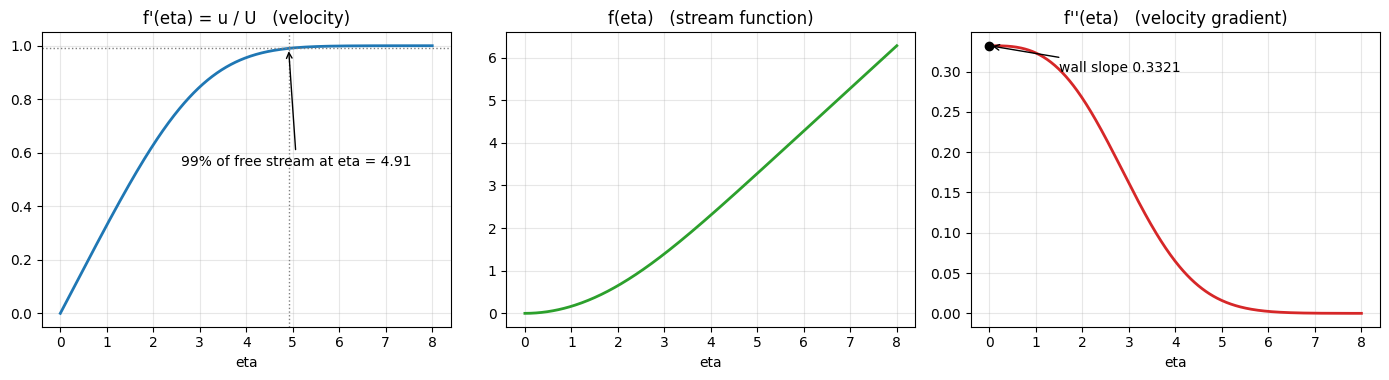

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].plot(eta_grid, f1_exact, lw=2)
axes[0].axhline(0.99, color="gray", ls=":", lw=1)
axes[0].axvline(ref_numbers["eta_99"], color="gray", ls=":", lw=1)
axes[0].annotate(f"99% of free stream at eta = {ref_numbers['eta_99']:.2f}",
                 (ref_numbers["eta_99"], 0.99), (2.6, 0.55), arrowprops=dict(arrowstyle="->"))
axes[0].set_title("f'(eta) = u / U   (velocity)")
axes[1].plot(eta_grid, f_exact, lw=2, color="tab:green")
axes[1].set_title("f(eta)   (stream function)")
axes[2].plot(eta_grid, f2_exact, lw=2, color="tab:red")
axes[2].scatter([0], [wall_slope_exact], color="k", zorder=3)
axes[2].annotate(f"wall slope {wall_slope_exact:.4f}", (0, wall_slope_exact), (1.5, 0.3), arrowprops=dict(arrowstyle="->"))
axes[2].set_title("f''(eta)   (velocity gradient)")
for ax in axes:
    ax.set_xlabel("eta")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## S6. From the dimensionless solution to a real plate
Because the solution is *similar* at every position, one curve covers every case. To get real numbers we use $\eta=y\sqrt{U/(\nu x)}$ and $u=U\,f'(\eta)$. The function below does it for any speed, fluid and distance and also reports the Reynolds number, the layer thickness and the skin friction.

In [5]:
def plate_numbers(U, nu, x, rho=1.2):
    # boundary-layer numbers for a flat plate at distance x from the front edge
    Re_x = U * x / nu
    kappa = np.sqrt(U / (nu * x))                        # 1 / length scale (per metre)
    return {
        "Re_x": Re_x,
        "kappa (1/m)": kappa,
        "delta_99 (mm)": 1000.0 * ref_numbers["eta_99"] / kappa,
        "displacement thickness (mm)": 1000.0 * ref_numbers["displacement integral"] / kappa,
        "wall velocity gradient (1/s)": U * kappa * wall_slope_exact,
        "skin friction c_f": 2.0 * wall_slope_exact / np.sqrt(Re_x),
        "wall shear stress (Pa)": rho * nu * U * kappa * wall_slope_exact,
    }

case = plate_numbers(U_inf, nu_air, x_station, rho_air)
print(f"Air at {U_inf} m/s, {x_station} m from the front edge:")
for key, value in case.items():
    print(f"  {key:30s}{value:14.4g}")

Air at 10.0 m/s, 0.5 m from the front edge:
  Re_x                               3.333e+05
  kappa (1/m)                             1155
  delta_99 (mm)                          4.252
  displacement thickness (mm)             1.49
  wall velocity gradient (1/s)            3834
  skin friction c_f                    0.00115
  wall shear stress (Pa)               0.06902


So the layer is about 4 mm thick there, as promised in section 1.

**Try it yourself (Jupyter or Colab).** The sliders below change the speed, distance and fluid, and redraw the real velocity profile. Notice how the layer thickens with distance but thins with speed, and how the Reynolds number tells you when the laminar model stops being trustworthy. If `ipywidgets` is not installed, the cell prints a hint and moves on.

In [ ]:
FLUIDS = {"air": (1.2, 1.5e-5), "water": (1000.0, 1.0e-6)}

def explore_plate(fluid="air", speed=10.0, distance=0.5):
    rho_f, nu_f = FLUIDS[fluid]
    info = plate_numbers(speed, nu_f, distance, rho_f)
    kappa = info["kappa (1/m)"]
    y_mm = 1000.0 * eta_grid.ravel() / kappa
    plt.figure(figsize=(8.5, 4.2))
    plt.plot(speed * f1_exact.ravel(), y_mm, lw=2.5)
    plt.axhline(info["delta_99 (mm)"], color="gray", ls="--", lw=1)
    plt.text(0.02 * speed, info["delta_99 (mm)"] * 1.03, f"delta_99 = {info['delta_99 (mm)']:.2f} mm", color="gray")
    plt.xlim(0, speed * 1.05)
    plt.xlabel("air speed u (m/s)" if fluid == "air" else "water speed u (m/s)")
    plt.ylabel("height above the plate y (mm)")
    state = "laminar (model valid)" if info["Re_x"] < 5e5 else "probably TURBULENT (model not valid)"
    plt.title(f"{fluid}, U = {speed:.1f} m/s, x = {distance:.2f} m:  Re_x = {info['Re_x']:.3g}  ->  {state}")
    plt.grid(alpha=0.3)
    plt.show()
    print(f"wall shear stress = {info['wall shear stress (Pa)']:.4g} Pa,  skin friction c_f = {info['skin friction c_f']:.4g}")

try:
    import ipywidgets as widgets
    widgets.interact(
        explore_plate,
        fluid=widgets.Dropdown(options=["air", "water"], value="air", description="fluid"),
        speed=widgets.FloatSlider(value=10.0, min=0.5, max=60.0, step=0.5, description="U (m/s)"),
        distance=widgets.FloatSlider(value=0.5, min=0.05, max=2.0, step=0.05, description="x (m)"),
    )
except ImportError:
    print("ipywidgets is not installed. Run: pip install ipywidgets")

interactive(children=(Dropdown(description='fluid', options=('air', 'water'), value='air'), FloatSlider(value=…

## S7. A picture of the boundary layer from above
The next helper builds a map of $u/U$ over the plate, with $x$ along the bottom and the height $y$ up the side. It works from any profile $f'(\eta)$ sampled on `eta_grid`, so we can feed it the reference now and neural networks later. The white dashed curve is the exact edge of the layer, $\delta_{99}(x)=\eta_{99}\sqrt{\nu x/U}$. The layer starts at nothing and thickens like $\sqrt x$.

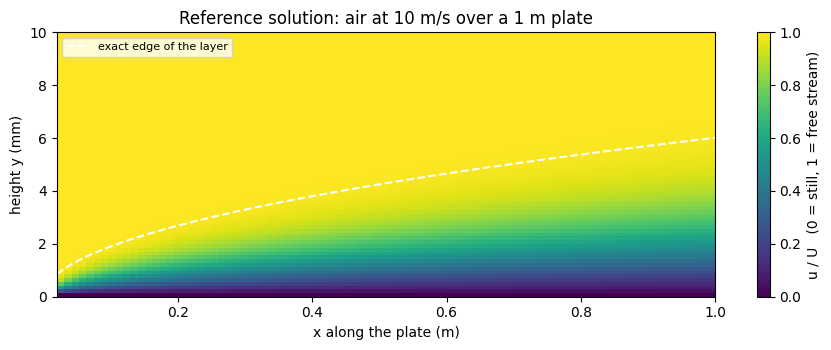

In [ ]:
MAP_X = np.linspace(0.02, plate_length, 90)                  # positions along the plate (m)
MAP_Y_MM = np.linspace(0.0, 10.0, 70)                        # heights (mm)
MAP_ETA = (MAP_Y_MM[:, None] / 1000.0) * np.sqrt(U_inf / (nu_air * MAP_X[None, :]))   # eta at every map point
DELTA99_CURVE_MM = 1000.0 * ref_numbers["eta_99"] * np.sqrt(nu_air * MAP_X / U_inf)


def flow_map(f1_profile):
    # u/U over the plate, from a profile f'(eta) given on eta_grid
    return np.interp(MAP_ETA, eta_grid.ravel(), np.asarray(f1_profile).ravel())


def draw_flow_map(ax, f1_profile, title="u / U over the plate"):
    image = ax.imshow(flow_map(f1_profile), origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1,
                      extent=[MAP_X[0], MAP_X[-1], MAP_Y_MM[0], MAP_Y_MM[-1]])
    ax.plot(MAP_X, DELTA99_CURVE_MM, "w--", lw=1.5, label="exact edge of the layer")
    ax.set_xlabel("x along the plate (m)")
    ax.set_ylabel("height y (mm)")
    ax.set_title(title)
    return image


fig, ax = plt.subplots(figsize=(9, 3.6))
img = draw_flow_map(ax, f1_exact, "Reference solution: air at 10 m/s over a 1 m plate")
ax.legend(loc="upper left", fontsize=8)
fig.colorbar(img, ax=ax, label="u / U   (0 = still, 1 = free stream)")
plt.tight_layout()
plt.show()

## S8. Measurements for the inverse problem
Section 12 describes a velocity profile measured at one station with noise and with nothing close to the wall. We create it here from the exact solution so that we know the truth. The case is the same air flow, at $x=0.5$ m, so $\kappa=\sqrt{U/(\nu x)}=1.155$ per millimetre. There are 14 readings between 0.6 mm and 6 mm, each with noise of 0.02 (2% of the free-stream speed), and **none below 0.6 mm**. Heights are in millimetres, so $\kappa$ is in "per millimetre".

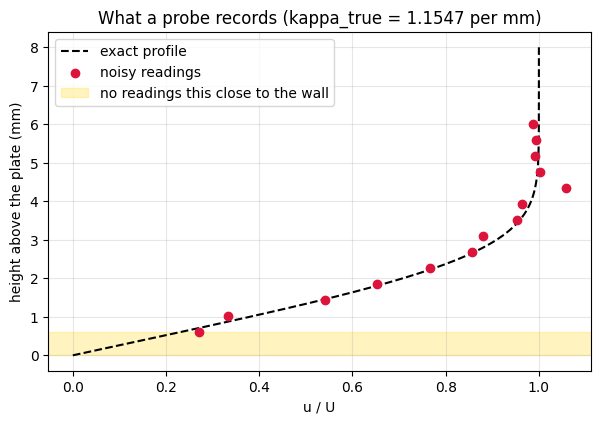

In [ ]:
kappa_true = np.sqrt(U_inf / (nu_air * x_station)) / 1000.0      # per millimetre
N_meas = 14
noise_level = 0.02

rng_meas = np.random.default_rng(3)
y_meas = np.linspace(0.6, 6.0, N_meas).reshape(-1, 1)           # heights (mm)
u_meas = ref(kappa_true * y_meas)[1] + noise_level * rng_meas.standard_normal(y_meas.shape)   # u/U with noise

y_dense = np.linspace(0.0, 8.0, 300)
plt.figure(figsize=(7, 4.4))
plt.plot(ref(kappa_true * y_dense)[1], y_dense, "k--", label="exact profile")
plt.scatter(u_meas, y_meas, color="crimson", zorder=3, label="noisy readings")
plt.axhspan(0, 0.6, color="gold", alpha=0.25, label="no readings this close to the wall")
plt.xlabel("u / U")
plt.ylabel("height above the plate (mm)")
plt.title(f"What a probe records (kappa_true = {kappa_true:.4f} per mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## S9. Helper functions: errors, snapshots, the video, the slider

These are used by both parts, so they live here.

* `rmse` measures an error. `make_snapshot_epochs` picks which epochs to record (many early, fewer later).
* `make_training_video` draws a two-column animation: the left and right networks are shown **side by side**. For each, it shows the velocity profile against the exact one, the boundary-layer map built from the network's current profile, and a strip with the network's wall slope against the exact value as training goes on. It saves a GIF with Pillow and an MP4 with `ffmpeg`.
* `convert_mp4_to_gif` turns an existing MP4 into a GIF.
* `snapshot_grid` is a still picture of a few moments in training (it shows on GitHub). `scrub_epochs` is a slider to move through training by hand.

Each "run" is a small dictionary holding a name, a colour, the saved profiles `f1` (one row per snapshot) and the saved wall slopes `wall`.

In [14]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def make_snapshot_epochs(epochs, n_snapshots=90):
    # epoch 0 plus a geometric spread up to the final epoch
    spread = np.unique(np.round(np.geomspace(1, epochs, n_snapshots)).astype(int))
    return sorted(set([0] + spread.tolist()))


def find_ffmpeg():
    path = shutil.which("ffmpeg")
    if path:
        return path
    try:
        import imageio_ffmpeg
        return imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        return None

In [ ]:
def make_training_video(epochs_saved, runs, mp4_path=None, gif_path=None, fps=12, hold_frames=18,
                        mp4_dpi=90, gif_dpi=60):
    # runs: a list of two dictionaries, each with keys "name", "color", "f1" (n_snap x n_grid), "wall" (n_snap)
    epochs_saved = np.asarray(epochs_saved)
    eta = eta_grid.ravel()
    fig = plt.figure(figsize=(12, 7.2))               # even pixel sizes, needed for MP4
    gs = fig.add_gridspec(3, 2, height_ratios=[2.0, 1.55, 1.15])
    ax_prof = [fig.add_subplot(gs[0, j]) for j in range(2)]
    ax_map = [fig.add_subplot(gs[1, j]) for j in range(2)]
    ax_wall = fig.add_subplot(gs[2, :])

    lines, images = [], []
    for j, run in enumerate(runs):
        ax = ax_prof[j]
        ax.plot(eta, f1_exact.ravel(), "k--", lw=1.3, label="exact profile")
        line, = ax.plot([], [], color=run["color"], lw=2.6, label="network")
        ax.set_title(run["name"], fontsize=12)
        ax.set_xlabel("eta")
        ax.set_ylabel("u / U  =  f'(eta)")
        ax.set_ylim(-0.25, 1.25)
        ax.grid(alpha=0.3)
        ax.legend(loc="lower right", fontsize=8)
        lines.append(line)
        images.append(draw_flow_map(ax_map[j], np.zeros_like(eta), "boundary layer from the network"))
    ax_map[0].legend(loc="upper left", fontsize=7)

    wall_all = np.concatenate([np.asarray(r["wall"]) for r in runs])
    low = min(-0.25, float(wall_all.min()) - 0.05)
    high = max(0.9, min(float(wall_all.max()), 1.5) + 0.05)
    ax_wall.set_xscale("log")
    ax_wall.set_xlim(1, epochs_saved.max() * 1.1)
    ax_wall.set_ylim(low, high)
    ax_wall.axhline(wall_slope_exact, color="k", ls="--", lw=1.2, label=f"exact wall slope {wall_slope_exact:.4f}")
    ax_wall.set_xlabel("epoch")
    ax_wall.set_ylabel("network's f''(0)")
    ax_wall.grid(alpha=0.3, which="both")
    curves, dots = [], []
    for run in runs:
        curve, = ax_wall.plot([], [], color=run["color"], lw=2, label=run["name"])
        dot, = ax_wall.plot([], [], "o", color=run["color"])
        curves.append(curve)
        dots.append(dot)
    ax_wall.legend(loc="lower right", fontsize=8)
    title = fig.suptitle("", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))

    epochs_plot = np.maximum(epochs_saved, 1)
    frames = list(range(len(epochs_saved))) + [len(epochs_saved) - 1] * hold_frames

    def update(i):
        artists = []
        for j, run in enumerate(runs):
            lines[j].set_data(eta, run["f1"][i])
            images[j].set_data(flow_map(run["f1"][i]))
            curves[j].set_data(epochs_plot[: i + 1], np.asarray(run["wall"])[: i + 1])
            dots[j].set_data([epochs_plot[i]], [run["wall"][i]])
            artists += [lines[j], images[j], curves[j], dots[j]]
        title.set_text(f"Training epoch {int(epochs_saved[i]):,}")
        return artists + [title]

    anim = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / fps, blit=False)

    if gif_path is not None:
        anim.save(str(gif_path), writer=animation.PillowWriter(fps=fps), dpi=gif_dpi)
        print(f"saved GIF: {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    if mp4_path is not None:
        ffmpeg = find_ffmpeg()
        if ffmpeg is None:
            print("ffmpeg was not found, so no MP4 was written. Install ffmpeg, or run: pip install imageio-ffmpeg")
        else:
            plt.rcParams["animation.ffmpeg_path"] = ffmpeg
            anim.save(str(mp4_path), writer=animation.FFMpegWriter(fps=fps, bitrate=2200), dpi=mp4_dpi)
            print(f"saved MP4: {mp4_path}  ({Path(mp4_path).stat().st_size / 1e6:.1f} MB)")
    plt.close(fig)
    return anim


def convert_mp4_to_gif(mp4_path, gif_path, fps=12, width=800):
    # convert an existing MP4 to a GIF with ffmpeg. The palette step keeps the colours clean.
    ffmpeg = find_ffmpeg()
    if ffmpeg is None:
        print("ffmpeg was not found, so the MP4 could not be converted.")
        return None
    filters = f"fps={fps},scale={width}:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse"
    subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", str(mp4_path), "-vf", filters, str(gif_path)], check=True)
    print(f"converted {mp4_path} -> {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    return gif_path

In [ ]:
def scrub_epochs(epochs_saved, runs):
    # epoch slider (needs ipywidgets in Jupyter or Colab).
    try:
        import ipywidgets as widgets
    except ImportError:
        print("ipywidgets is not installed. Run: pip install ipywidgets")
        return

    def draw(snapshot):
        fig, axes = plt.subplots(1, len(runs), figsize=(6 * len(runs), 3.8), sharey=True)
        for ax, run in zip(np.atleast_1d(axes), runs):
            ax.plot(eta_grid, f1_exact, "k--", lw=1.2, label="exact")
            ax.plot(eta_grid, run["f1"][snapshot], color=run["color"], lw=2.5, label="network")
            ax.set_title(f"{run['name']}\nwall slope f''(0) = {run['wall'][snapshot]:.3f}  (exact {wall_slope_exact:.3f})")
            ax.set_xlabel("eta")
            ax.set_ylim(-0.25, 1.25)
            ax.grid(alpha=0.3)
        np.atleast_1d(axes)[0].set_ylabel("u / U")
        np.atleast_1d(axes)[0].legend(loc="lower right", fontsize=8)
        fig.suptitle(f"epoch {int(epochs_saved[snapshot]):,}", fontweight="bold")
        plt.tight_layout()
        plt.show()

    slider = widgets.SelectionSlider(options=[(f"{int(e):,}", i) for i, e in enumerate(epochs_saved)],
                                     description="epoch", layout=widgets.Layout(width="85%"))
    widgets.interact(draw, snapshot=slider)


def snapshot_grid(epochs_saved, runs, picks=(0, 30, 300, 2000, 8000)):
    # still picture of a few moments in training (it also shows on GitHub, where sliders do not).
    epochs_saved = np.asarray(epochs_saved)
    idx = [int(np.argmin(np.abs(epochs_saved - p))) for p in picks]
    fig, axes = plt.subplots(len(runs), len(idx), figsize=(3.2 * len(idx), 2.8 * len(runs)),
                             sharex=True, sharey=True, squeeze=False)
    for col, i in enumerate(idx):
        for row, run in enumerate(runs):
            ax = axes[row, col]
            ax.plot(eta_grid, f1_exact, "k--", lw=1)
            ax.plot(eta_grid, run["f1"][i], color=run["color"], lw=2)
            ax.set_ylim(-0.25, 1.25)
            ax.grid(alpha=0.3)
            if row == 0:
                ax.set_title(f"epoch {int(epochs_saved[i]):,}", fontsize=11)
            if col == 0:
                ax.set_ylabel(run["name"].split("(")[0].strip() + "\nu / U")
            if row == len(runs) - 1:
                ax.set_xlabel("eta")
    plt.tight_layout()
    plt.show()

---
---
# Part A: From scratch with NumPy

Only NumPy (arrays and matrix products), SciPy (for the reference solution and a small optimiser in one place) and Matplotlib. No machine-learning library and no automatic differentiation. We write:

1. a network that returns $\hat f$, $\hat f'$, $\hat f''$ and $\hat f'''$ in one forward pass,
2. the loss (equation plus boundary conditions),
3. the gradients by hand, and a test of them,
4. the Adam optimiser,
5. training, with snapshots for the video,
6. a survey of random starts, the warm-start fix, and an inverse problem.

## A1. The network and its forward pass with three derivatives

The network is 1 → 32 → 32 → 32 → 1 with $\tanh$ in the hidden layers. Weights live in a dictionary (`W0, b0, W1, b1, ...`) and start from the Xavier-uniform rule with zero biases, as in the oscillator notebook.

The forward pass carries four things through every layer: the value and its first, second and third derivative with respect to $\eta$. The formulas are the ones derived in background section 10. In the code, `P, P1, P2, P3` are what arrives at a layer; `Z, Z1, Z2, Z3` are after the matrix product; `A, A1, A2, A3` come out of the $\tanh$; and `S` is $1-\mathbf A^2$. We also store three combinations that will be reused in the backward pass:

$$
\mathbf U=-2\mathbf A\mathbf S,\qquad
\mathbf V=-6\mathbf A\mathbf S,\qquad
\mathbf T=-2\mathbf S(1-3\mathbf A^2),
$$
so that the activation step reads $\ddot{\mathbf A}=\mathbf S\ddot{\mathbf Z}+\mathbf U\dot{\mathbf Z}^2$ and $\dddot{\mathbf A}=\mathbf S\dddot{\mathbf Z}+\mathbf V\dot{\mathbf Z}\ddot{\mathbf Z}+\mathbf T\dot{\mathbf Z}^3$.

In [6]:
def init_params(sizes, seed=0):
    # Xavier-uniform weights, zero biases. sizes = (1, 32, 32, 32, 1) for example.
    rng = np.random.default_rng(seed)
    params = {}
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        limit = np.sqrt(6.0 / (n_in + n_out))
        params[f"W{i}"] = rng.uniform(-limit, limit, size=(n_in, n_out))
        params[f"b{i}"] = np.zeros((1, n_out))
    return params


def n_layers(params):
    return sum(1 for key in params if key.startswith("W"))


def forward_jets(params, eta):
    # returns f, f', f'', f''' for a batch of points eta with shape (N, 1), plus stored arrays for backprop.
    L = n_layers(params)
    P, P1, P2, P3 = eta, np.ones_like(eta), np.zeros_like(eta), np.zeros_like(eta)   # input: a0 = eta, a0' = 1
    caches = []
    for l in range(L - 1):                                    # hidden layers
        W, b = params[f"W{l}"], params[f"b{l}"]
        Z, Z1, Z2, Z3 = P @ W + b, P1 @ W, P2 @ W, P3 @ W    # linear step
        A = np.tanh(Z)
        S = 1.0 - A**2
        U = -2.0 * A * S
        V = -6.0 * A * S
        T = -2.0 * S * (1.0 - 3.0 * A**2)
        A1 = S * Z1
        A2 = S * Z2 + U * Z1**2
        A3 = S * Z3 + V * Z1 * Z2 + T * Z1**3
        caches.append((P, P1, P2, P3, Z1, Z2, Z3, A, S, U, V, T))
        P, P1, P2, P3 = A, A1, A2, A3
    W, b = params[f"W{L-1}"], params[f"b{L-1}"]               # last layer is linear
    X, X1, X2, X3 = P @ W + b, P1 @ W, P2 @ W, P3 @ W
    caches.append((P, P1, P2, P3))
    return X, X1, X2, X3, caches

## A2. The loss

All the points go into one batch so that one forward pass handles everything: first the collocation points (where the equation is checked), then the wall ($\eta=0$), then the far edge ($\eta=\eta_{\max}$), then, if we have any, measurement points. `make_batch` stacks them and remembers where each group sits.

The loss follows section 9: the squared ODE residual $\hat f'''+\tfrac12\hat f\hat f''$ at the collocation points, the three boundary errors, and an optional data term $(\hat f'-\text{target})^2$. We use the data term in two places only: a short warm-up and the inverse problem. The weights are given as `lam = (lam_ode, lam_bc, lam_data)`.

In [7]:
def make_batch(eta_ode, eta_data=None, f1_data=None):
    # stack: collocation points | eta = 0 | eta = ETA_MAX | measurement points (optional)
    pieces = [eta_ode, np.zeros((1, 1)), np.full((1, 1), ETA_MAX)]
    n_data = 0
    if eta_data is not None:
        pieces.append(eta_data)
        n_data = len(eta_data)
    return {"eta": np.vstack(pieces), "n_ode": len(eta_ode), "n_data": n_data, "f1_data": f1_data}


def loss_terms(params, batch):
    # the three loss pieces (equation, boundary, data) without weights; used for checking and printing
    no, nd = batch["n_ode"], batch["n_data"]
    X, X1, X2, X3, _ = forward_jets(params, batch["eta"])
    r_ode = X3[:no] + 0.5 * X[:no] * X2[:no]
    l_ode = np.mean(r_ode**2)
    l_bc = np.mean(X[no:no+1]**2) + np.mean(X1[no:no+1]**2) + np.mean((X1[no+1:no+2] - 1.0)**2)
    l_data = np.mean((X1[no+2:no+2+nd] - batch["f1_data"])**2) if nd else 0.0
    return l_ode, l_bc, l_data


def total_loss(params, batch, lam):
    l_ode, l_bc, l_data = loss_terms(params, batch)
    return lam[0] * l_ode + lam[1] * l_bc + lam[2] * l_data

## A3. Gradients by hand: complete chain-rule derivation

This section derives every parameter gradient used by the NumPy implementation in `backward_jets` and `loss_and_grads`. No automatic differentiation is used. We differentiate the scalar loss with respect to the network outputs, then propagate those gradients through the final linear layer and each hidden layer, including the first, second, and third derivatives with respect to the similarity coordinate $\eta$.

The governing Blasius equation and boundary conditions are

$$
f'''+\frac12 f f''=0,\qquad
f(0)=0,\qquad f'(0)=0,\qquad f'(\eta_{\max})=1.
$$

Throughout, array products such as $\mathbf A^2$ are element-wise, and $\odot$ explicitly denotes element-wise multiplication. Matrix products are written by juxtaposition. Gradients are defined as derivatives of the scalar total loss with respect to each array.

### A3.1. Forward-pass notation

Let the network have $L-1$ hidden layers and one final linear layer. For hidden layer $\ell$, the forward equations are

$$
\begin{aligned}
\mathbf Z_\ell&=\mathbf P_\ell\mathbf W_\ell+\mathbf b_\ell,\\
\mathbf A_\ell&=\tanh(\mathbf Z_\ell),\\
\mathbf S_\ell&=1-\mathbf A_\ell^2,\\
\mathbf U_\ell&=-2\mathbf A_\ell\odot\mathbf S_\ell,\\
\mathbf V_\ell&=-6\mathbf A_\ell\odot\mathbf S_\ell,\\
\mathbf T_\ell&=-2\mathbf S_\ell\odot(1-3\mathbf A_\ell^2).
\end{aligned}
$$

The incoming value and its derivatives are $\mathbf P_\ell,\mathbf P_{\ell,1},\mathbf P_{\ell,2},\mathbf P_{\ell,3}$. The corresponding linear outputs are

$$
\begin{aligned}
\mathbf Z_{\ell,1}&=\mathbf P_{\ell,1}\mathbf W_\ell,\\
\mathbf Z_{\ell,2}&=\mathbf P_{\ell,2}\mathbf W_\ell,\\
\mathbf Z_{\ell,3}&=\mathbf P_{\ell,3}\mathbf W_\ell.
\end{aligned}
$$

Differentiating $\tanh$ with respect to $\eta$ gives the three derivative outputs

$$
\begin{aligned}
\mathbf A_{\ell,1}
&=\mathbf S_\ell\odot\mathbf Z_{\ell,1},\\
\mathbf A_{\ell,2}
&=\mathbf S_\ell\odot\mathbf Z_{\ell,2}
+\mathbf U_\ell\odot\mathbf Z_{\ell,1}^{\,2},\\
\mathbf A_{\ell,3}
&=\mathbf S_\ell\odot\mathbf Z_{\ell,3}
+\mathbf V_\ell\odot\mathbf Z_{\ell,1}\odot\mathbf Z_{\ell,2}
+\mathbf T_\ell\odot\mathbf Z_{\ell,1}^{\,3}.
\end{aligned}
$$

The input is $\eta$, so $\mathbf P_0=\eta$, $\mathbf P_{0,1}=\mathbf 1$, and $\mathbf P_{0,2}=\mathbf P_{0,3}=\mathbf 0$.

For the final linear layer, whose incoming arrays are denoted $\mathbf P,\mathbf P_1,\mathbf P_2,\mathbf P_3$,

$$
\begin{aligned}
\mathbf X&=\mathbf P\mathbf W+\mathbf b,\\
\mathbf X_1&=\mathbf P_1\mathbf W,\\
\mathbf X_2&=\mathbf P_2\mathbf W,\\
\mathbf X_3&=\mathbf P_3\mathbf W.
\end{aligned}
$$

Thus $\mathbf X,\mathbf X_1,\mathbf X_2,\mathbf X_3$ represent $\hat f,\hat f',\hat f'',\hat f'''$, respectively.

### A3.2. Step 1 — Derive the gradients at the network outputs

The total loss is

$$
\mathcal L=\lambda_{\mathrm{ODE}}\mathcal L_{\mathrm{ODE}}
+\lambda_{\mathrm{BC}}\mathcal L_{\mathrm{BC}}
+\lambda_{\mathrm{data}}\mathcal L_{\mathrm{data}}.
$$

The output gradients are

$$
\mathbf g_X=\frac{\partial\mathcal L}{\partial\mathbf X},\quad
\mathbf g_{X1}=\frac{\partial\mathcal L}{\partial\mathbf X_1},\quad
\mathbf g_{X2}=\frac{\partial\mathcal L}{\partial\mathbf X_2},\quad
\mathbf g_{X3}=\frac{\partial\mathcal L}{\partial\mathbf X_3}.
$$

Each loss term contributes only to the output rows it uses. The implementation places all points in one batch: collocation points first, then the wall point, the far-edge point, and optional data points.

#### A3.2.1. ODE residual loss

At each collocation point, define

$$
r_i=X_{3,i}+\frac12 X_iX_{2,i},\qquad
\mathcal L_{\mathrm{ODE}}=\frac1{N_c}\sum_{i=1}^{N_c}r_i^2.
$$

First differentiate the squared residual with respect to $r_i$:

$$
\begin{aligned}
\frac{\partial\mathcal L_{\mathrm{ODE}}}{\partial r_i}
&=\frac{\partial}{\partial r_i}
\left(\frac1{N_c}\sum_{j=1}^{N_c}r_j^2\right)\\
&=\frac1{N_c}\,2r_i\\
&=\frac{2r_i}{N_c}.
\end{aligned}
$$

The residual depends on $X_i$, $X_{2,i}$, and $X_{3,i}$. Differentiating with respect to $X_i$, while holding the other output components fixed, gives

$$
\begin{aligned}
\frac{\partial r_i}{\partial X_i}
&=\frac{\partial}{\partial X_i}
\left(X_{3,i}+\frac12X_iX_{2,i}\right)\\
&=0+\frac12X_{2,i}\\
&=\frac12X_{2,i}.
\end{aligned}
$$

The product rule is being applied to $X_iX_{2,i}$; in this partial derivative $X_{2,i}$ is held fixed. Therefore,

$$
\begin{aligned}
\frac{\partial\mathcal L_{\mathrm{ODE}}}{\partial X_i}
&=\frac{\partial\mathcal L_{\mathrm{ODE}}}{\partial r_i}
\frac{\partial r_i}{\partial X_i}\\
&=\frac{2r_i}{N_c}\frac12X_{2,i}.
\end{aligned}
$$

Including the loss weight,

$$
\boxed{(g_X^{\mathrm{ODE}})_i
=\lambda_{\mathrm{ODE}}\frac{2r_i}{N_c}\frac12X_{2,i}.}
$$

Next, differentiate the residual with respect to $X_{2,i}$, holding $X_i$ and $X_{3,i}$ fixed:

$$
\begin{aligned}
\frac{\partial r_i}{\partial X_{2,i}}
&=\frac{\partial}{\partial X_{2,i}}
\left(X_{3,i}+\frac12X_iX_{2,i}\right)\\
&=0+\frac12X_i\\
&=\frac12X_i.
\end{aligned}
$$

The chain rule gives

$$
\boxed{(g_{X2}^{\mathrm{ODE}})_i
=\lambda_{\mathrm{ODE}}\frac{2r_i}{N_c}\frac12X_i.}
$$

Finally, $r_i$ depends linearly on $X_{3,i}$, so

$$
\frac{\partial r_i}{\partial X_{3,i}}=1
$$

and hence

$$
\boxed{(g_{X3}^{\mathrm{ODE}})_i
=\lambda_{\mathrm{ODE}}\frac{2r_i}{N_c}.}
$$

There is no direct ODE-loss contribution to $g_{X1}$, because the Blasius residual $f'''+\frac12ff''$ does not contain $f'$.

In vector form, on the collocation rows,

$$
\begin{aligned}
\mathbf g_{\mathrm{res}}&=\lambda_{\mathrm{ODE}}\frac{2}{N_c}\mathbf r,\\
\mathbf g_X&\mathrel{+}=\frac12\mathbf g_{\mathrm{res}}\odot\mathbf X_2,\\
\mathbf g_{X2}&\mathrel{+}=\frac12\mathbf g_{\mathrm{res}}\odot\mathbf X,\\
\mathbf g_{X3}&\mathrel{+}=\mathbf g_{\mathrm{res}}.
\end{aligned}
$$

These are exactly the three updates made by `loss_and_grads`.

#### A3.2.2. Boundary-condition loss

The boundary loss is

$$
\mathcal L_{\mathrm{BC}}
=X(0)^2+X_1(0)^2+\big(X_1(\eta_{\max})-1\big)^2.
$$

For the wall value, let $b_f=X(0)$. Then

$$
\begin{aligned}
\frac{\partial b_f^2}{\partial X(0)}
&=\frac{\partial b_f^2}{\partial b_f}
\frac{\partial b_f}{\partial X(0)}\\
&=2b_f\cdot1\\
&=2X(0).
\end{aligned}
$$

Thus the wall-value contribution is

$$
\boxed{g_X(0)\mathrel{+}=2\lambda_{\mathrm{BC}}X(0).}
$$

For the wall derivative, let $b_{f1}=X_1(0)$. Similarly,

$$
\begin{aligned}
\frac{\partial b_{f1}^2}{\partial X_1(0)}
&=\frac{\partial b_{f1}^2}{\partial b_{f1}}
\frac{\partial b_{f1}}{\partial X_1(0)}\\
&=2b_{f1}\cdot1\\
&=2X_1(0).
\end{aligned}
$$

Therefore,

$$
\boxed{g_{X1}(0)\mathrel{+}=2\lambda_{\mathrm{BC}}X_1(0).}
$$

At the far edge, define $b_{\mathrm{far}}=X_1(\eta_{\max})-1$. Since

$$
\frac{\partial b_{\mathrm{far}}}{\partial X_1(\eta_{\max})}=1,
$$

the chain rule gives

$$
\boxed{
g_{X1}(\eta_{\max})\mathrel{+}=
2\lambda_{\mathrm{BC}}\big(X_1(\eta_{\max})-1\big).
}
$$

The boundary loss does not depend on $X_2$ or $X_3$, so it contributes no direct terms to $g_{X2}$ or $g_{X3}$.

#### A3.2.3. Optional data loss

When measurement data are present, the loss is

$$
\mathcal L_{\mathrm{data}}=\frac1{N_d}
\sum_{i=1}^{N_d}(X_{1,i}-y_i)^2,
$$

where $y_i$ is the measured velocity profile $u/U$ at the corresponding similarity coordinate. Define $q_i=X_{1,i}-y_i$. Then

$$
\begin{aligned}
\frac{\partial\mathcal L_{\mathrm{data}}}{\partial X_{1,i}}
&=\frac{\partial\mathcal L_{\mathrm{data}}}{\partial q_i}
\frac{\partial q_i}{\partial X_{1,i}}\\
&=\frac{2q_i}{N_d}\cdot1\\
&=\frac{2}{N_d}(X_{1,i}-y_i).
\end{aligned}
$$

Including the data weight,

$$
\boxed{
(g_{X1}^{\mathrm{data}})_i
=\lambda_{\mathrm{data}}\frac{2}{N_d}(X_{1,i}-y_i).
}
$$

The data loss depends on $X_1$, not directly on $X$, $X_2$, or $X_3$. It therefore contributes only to $g_{X1}$.

#### A3.2.4. Accumulate output gradients

All gradients start at zero. The contributions from the different loss terms are added at their corresponding batch rows:

$$
\begin{aligned}
\mathbf g_X&=\mathbf g_X^{\mathrm{ODE}}
+\mathbf g_X^{\mathrm{BC}},\\
\mathbf g_{X1}&=\mathbf g_{X1}^{\mathrm{BC}}
+\mathbf g_{X1}^{\mathrm{data}},\\
\mathbf g_{X2}&=\mathbf g_{X2}^{\mathrm{ODE}},\\
\mathbf g_{X3}&=\mathbf g_{X3}^{\mathrm{ODE}}.
\end{aligned}
$$

Terms that do not apply to a particular row are zero. In particular, data rows have a contribution to $g_{X1}$ only when data are supplied.

### A3.3. Step 2 — Backpropagate through the final linear layer

The final layer is linear:

$$
\begin{aligned}
\mathbf X&=\mathbf P\mathbf W+\mathbf b,\\
\mathbf X_1&=\mathbf P_1\mathbf W,\\
\mathbf X_2&=\mathbf P_2\mathbf W,\\
\mathbf X_3&=\mathbf P_3\mathbf W.
\end{aligned}
$$

The same weight matrix $\mathbf W$ appears in all four equations, so its gradient is the sum of four contributions.

For clarity, consider one element $W_{qj}$. For each sample $i$,

$$
\begin{aligned}
X_{ij}&=\sum_qP_{iq}W_{qj}+b_j,\\
(X_1)_{ij}&=\sum_q(P_1)_{iq}W_{qj},\\
(X_2)_{ij}&=\sum_q(P_2)_{iq}W_{qj},\\
(X_3)_{ij}&=\sum_q(P_3)_{iq}W_{qj}.
\end{aligned}
$$

The multivariable chain rule gives

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial W_{qj}}
&=\sum_i\frac{\partial\mathcal L}{\partial X_{ij}}
\frac{\partial X_{ij}}{\partial W_{qj}}\\
&\quad+\sum_i\frac{\partial\mathcal L}{\partial (X_1)_{ij}}
\frac{\partial (X_1)_{ij}}{\partial W_{qj}}\\
&\quad+\sum_i\frac{\partial\mathcal L}{\partial (X_2)_{ij}}
\frac{\partial (X_2)_{ij}}{\partial W_{qj}}\\
&\quad+\sum_i\frac{\partial\mathcal L}{\partial (X_3)_{ij}}
\frac{\partial (X_3)_{ij}}{\partial W_{qj}}.
\end{aligned}
$$

From the forward equations,

$$
\begin{aligned}
\frac{\partial X_{ij}}{\partial W_{qj}}&=P_{iq},\\
\frac{\partial (X_1)_{ij}}{\partial W_{qj}}&=(P_1)_{iq},\\
\frac{\partial (X_2)_{ij}}{\partial W_{qj}}&=(P_2)_{iq},\\
\frac{\partial (X_3)_{ij}}{\partial W_{qj}}&=(P_3)_{iq}.
\end{aligned}
$$

Substituting these partial derivatives,

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial W_{qj}}
&=\sum_iP_{iq}(g_X)_{ij}
+\sum_i(P_1)_{iq}(g_{X1})_{ij}\\
&\quad+\sum_i(P_2)_{iq}(g_{X2})_{ij}
+\sum_i(P_3)_{iq}(g_{X3})_{ij}.
\end{aligned}
$$

In matrix notation,

$$
\boxed{
\frac{\partial\mathcal L}{\partial\mathbf W}
=\mathbf P^\top\mathbf g_X
+\mathbf P_1^\top\mathbf g_{X1}
+\mathbf P_2^\top\mathbf g_{X2}
+\mathbf P_3^\top\mathbf g_{X3}.
}
$$

For the bias, only the value equation contains $\mathbf b$. Its partial derivatives are

$$
\frac{\partial X_{ij}}{\partial b_j}=1,\qquad
\frac{\partial (X_1)_{ij}}{\partial b_j}
=\frac{\partial (X_2)_{ij}}{\partial b_j}
=\frac{\partial (X_3)_{ij}}{\partial b_j}=0.
$$

The zero derivatives follow because a constant bias vanishes when differentiated with respect to \(\eta\). Therefore,

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial b_j}
&=\sum_i(g_X)_{ij}\cdot1
+\sum_i(g_{X1})_{ij}\cdot0\\
&\quad+\sum_i(g_{X2})_{ij}\cdot0
+\sum_i(g_{X3})_{ij}\cdot0\\
&=\sum_i(g_X)_{ij}.
\end{aligned}
$$

Hence,

$$
\boxed{
\frac{\partial\mathcal L}{\partial\mathbf b}
=\operatorname{sum}_{\mathrm{rows}}(\mathbf g_X).
}
$$

The four gradients passed to the preceding layer are obtained by differentiating each linear equation with respect to its input:

$$
\boxed{
\begin{aligned}
\mathbf g_P&=\mathbf g_X\mathbf W^\top,\\
\mathbf g_{P1}&=\mathbf g_{X1}\mathbf W^\top,\\
\mathbf g_{P2}&=\mathbf g_{X2}\mathbf W^\top,\\
\mathbf g_{P3}&=\mathbf g_{X3}\mathbf W^\top.
\end{aligned}
}
$$

These are the incoming gradients for the final hidden layer.

### A3.4. Step 3 — Differentiate the hidden-layer derivative equations

We now derive the most involved part of the backward pass. For one hidden layer, suppress the layer subscript and write

$$
\begin{aligned}
A&=\tanh Z,\qquad S=1-A^2,\\
A_1&=SZ_1,\\
A_2&=SZ_2+UZ_1^2,\\
A_3&=SZ_3+VZ_1Z_2+TZ_1^3,
\end{aligned}
$$

where all products in these equations are element-wise, and

$$
U=-2AS,\qquad V=-6AS,\qquad T=-2S(1-3A^2).
$$

The incoming gradients are

$$
g_A=\frac{\partial\mathcal L}{\partial A},\quad
g_{A1}=\frac{\partial\mathcal L}{\partial A_1},\quad
g_{A2}=\frac{\partial\mathcal L}{\partial A_2},\quad
g_{A3}=\frac{\partial\mathcal L}{\partial A_3}.
$$

We seek gradients with respect to $Z,Z_1,Z_2,Z_3$. Because $A_1,A_2,A_3$ share intermediate quantities $A,S,U,V,T$, we must accumulate every path into the appropriate gradient.

#### A3.4.1. Derivatives of the intermediate functions

First,

$$
S=1-A^2
\quad\Longrightarrow\quad
\boxed{\frac{dS}{dA}=-2A.}
$$

Next, use $U=-2A(1-A^2)=-2A+2A^3$:

$$
\begin{aligned}
\frac{dU}{dA}
&=\frac{d}{dA}(-2A+2A^3)\\
&=-2+6A^2.
\end{aligned}
$$

Thus,

$$
\boxed{U'=-2+6A^2.}
$$

Similarly, $V=-6A(1-A^2)=-6A+6A^3$, so

$$
\begin{aligned}
\frac{dV}{dA}
&=\frac{d}{dA}(-6A+6A^3)\\
&=-6+18A^2,
\end{aligned}
$$

and

$$
\boxed{V'=-6+18A^2.}
$$

Finally,

$$
\begin{aligned}
T&=-2(1-A^2)(1-3A^2)\\
&=-2(1-4A^2+3A^4)\\
&=-2+8A^2-6A^4.
\end{aligned}
$$

Therefore,

$$
\begin{aligned}
\frac{dT}{dA}
&=16A-24A^3,
\end{aligned}
$$

so

$$
\boxed{T'=16A-24A^3.}
$$

We will use the shorthand $S',U',V',T'$ for these derivatives with respect to $A$. They are not derivatives with respect to $\eta$.

#### A3.4.2. Gradient with respect to $Z_1$

The variable $Z_1$ appears in $A_1,A_2,A_3$. Differentiate each equation while holding its other inputs fixed.

From $A_1=SZ_1$,

$$
\frac{\partial A_1}{\partial Z_1}=S.
$$

From $A_2=SZ_2+UZ_1^2$,

$$
\begin{aligned}
\frac{\partial A_2}{\partial Z_1}
&=\frac{\partial}{\partial Z_1}(SZ_2+UZ_1^2)\\
&=0+U\cdot2Z_1\\
&=2UZ_1.
\end{aligned}
$$

From $A_3=SZ_3+VZ_1Z_2+TZ_1^3$,

$$
\begin{aligned}
\frac{\partial A_3}{\partial Z_1}
&=0+VZ_2+T\cdot3Z_1^2\\
&=VZ_2+3TZ_1^2.
\end{aligned}
$$

The multivariable chain rule now gives

$$
\begin{aligned}
g_{Z1}
&=\frac{\partial\mathcal L}{\partial Z_1}\\
&=g_{A1}\frac{\partial A_1}{\partial Z_1}
+g_{A2}\frac{\partial A_2}{\partial Z_1}
+g_{A3}\frac{\partial A_3}{\partial Z_1}\\
&=g_{A1}S+g_{A2}(2UZ_1)
+g_{A3}(VZ_2+3TZ_1^2).
\end{aligned}
$$

Thus,

$$
\boxed{
g_{Z1}=g_{A1}S+2g_{A2}UZ_1
+g_{A3}(VZ_2+3TZ_1^2).
}
$$

#### A3.4.3. Gradient with respect to $Z_2$

The variable $Z_2$ appears in $A_2$ and $A_3$. First,

$$
A_2=SZ_2+UZ_1^2
\quad\Longrightarrow\quad
\frac{\partial A_2}{\partial Z_2}=S.
$$

Next,

$$
A_3=SZ_3+VZ_1Z_2+TZ_1^3
\quad\Longrightarrow\quad
\frac{\partial A_3}{\partial Z_2}=VZ_1.
$$

The chain rule gives

$$
\begin{aligned}
g_{Z2}
&=g_{A2}\frac{\partial A_2}{\partial Z_2}
+g_{A3}\frac{\partial A_3}{\partial Z_2}\\
&=g_{A2}S+g_{A3}VZ_1.
\end{aligned}
$$

Therefore,

$$
\boxed{g_{Z2}=g_{A2}S+g_{A3}VZ_1.}
$$

#### A3.4.4. Gradient with respect to $Z_3$

Only $A_3$ depends on $Z_3$, and

$$
\frac{\partial A_3}{\partial Z_3}=S.
$$

Hence,

$$
\boxed{g_{Z3}=g_{A3}S.}
$$

#### A3.4.5. Gradient with respect to $A$: collect every path

The variable $A$ affects the three derivative outputs in two ways:

1. Directly through the coefficients $S,U,V,T$.
2. Through the activation itself, which is also an output with incoming gradient $g_A$.

We first collect the contributions through $S,U,V,T$.

From $A_1=SZ_1$,

$$
\begin{aligned}
\frac{\partial A_1}{\partial A}
&=\frac{dS}{dA}Z_1\\
&=S'Z_1.
\end{aligned}
$$

From $A_2=SZ_2+UZ_1^2$,

$$
\begin{aligned}
\frac{\partial A_2}{\partial A}
&=\frac{dS}{dA}Z_2+\frac{dU}{dA}Z_1^2\\
&=S'Z_2+U'Z_1^2.
\end{aligned}
$$

From $A_3=SZ_3+VZ_1Z_2+TZ_1^3$,

$$
\begin{aligned}
\frac{\partial A_3}{\partial A}
&=\frac{dS}{dA}Z_3
+\frac{dV}{dA}Z_1Z_2
+\frac{dT}{dA}Z_1^3\\
&=S'Z_3+V'Z_1Z_2+T'Z_1^3.
\end{aligned}
$$

The chain rule says that the contribution to $\partial\mathcal L/\partial A$ through these three paths is

$$
\begin{aligned}
g_A^{(\mathrm{derivatives})}
&=g_{A1}\frac{\partial A_1}{\partial A}
+g_{A2}\frac{\partial A_2}{\partial A}
+g_{A3}\frac{\partial A_3}{\partial A}\\
&=g_{A1}S'Z_1\\
&\quad+g_{A2}(S'Z_2+U'Z_1^2)\\
&\quad+g_{A3}(S'Z_3+V'Z_1Z_2+T'Z_1^3).
\end{aligned}
$$

There is also the incoming gradient $g_A$ from the direct activation output. Therefore, the total activation gradient is

$$
\boxed{
\begin{aligned}
g_{A,\mathrm{total}}
&=g_A+g_{A1}S'Z_1\\
&\quad+g_{A2}(S'Z_2+U'Z_1^2)\\
&\quad+g_{A3}(S'Z_3+V'Z_1Z_2+T'Z_1^3).
\end{aligned}
}
$$

This is a sum of four paths: the direct path through $A$, plus the paths through $A_1$, $A_2$, and $A_3$. All are required.

#### A3.4.6. Gradient with respect to $Z$

The activation is $A=\tanh Z$, so

$$
\begin{aligned}
\frac{\partial A}{\partial Z}
&=\frac{d}{dZ}\tanh Z\\
&=1-\tanh^2Z\\
&=1-A^2\\
&=S.
\end{aligned}
$$

Applying the chain rule to the total activation gradient,

$$
\begin{aligned}
g_Z
&=\frac{\partial\mathcal L}{\partial Z}\\
&=\frac{\partial\mathcal L}{\partial A}
\frac{\partial A}{\partial Z}\\
&=g_{A,\mathrm{total}}S.
\end{aligned}
$$

Therefore,

$$
\boxed{g_Z=g_{A,\mathrm{total}}S.}
$$

Combining the results for this hidden layer, the four gradients with respect to its linear outputs are

$$
\boxed{
\begin{aligned}
g_Z&=Sg_{A,\mathrm{total}},\\
g_{Z1}&=g_{A1}S+2g_{A2}UZ_1
+g_{A3}(VZ_2+3TZ_1^2),\\
g_{Z2}&=g_{A2}S+g_{A3}VZ_1,\\
g_{Z3}&=g_{A3}S.
\end{aligned}
}
$$

All products in these element-wise expressions are element-wise. These equations correspond directly to the calculations in `backward_jets`.

### A3.5. Step 4 — Backpropagate through a hidden layer's linear transformation

The linear part of a hidden layer is

$$
\begin{aligned}
\mathbf Z&=\mathbf P\mathbf W+\mathbf b,\\
\mathbf Z_1&=\mathbf P_1\mathbf W,\\
\mathbf Z_2&=\mathbf P_2\mathbf W,\\
\mathbf Z_3&=\mathbf P_3\mathbf W.
\end{aligned}
$$

The incoming gradients from the activation calculations are $g_Z,g_{Z1},g_{Z2},g_{Z3}$.

For an individual weight $W_{qj}$, expand the equations:

$$
\begin{aligned}
Z_{ij}&=\sum_qP_{iq}W_{qj}+b_j,\\
(Z_1)_{ij}&=\sum_q(P_1)_{iq}W_{qj},\\
(Z_2)_{ij}&=\sum_q(P_2)_{iq}W_{qj},\\
(Z_3)_{ij}&=\sum_q(P_3)_{iq}W_{qj}.
\end{aligned}
$$

The chain rule accumulates all four paths:

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial W_{qj}}
&=\sum_i(g_Z)_{ij}\frac{\partial Z_{ij}}{\partial W_{qj}}\\
&\quad+\sum_i(g_{Z1})_{ij}
\frac{\partial(Z_1)_{ij}}{\partial W_{qj}}\\
&\quad+\sum_i(g_{Z2})_{ij}
\frac{\partial(Z_2)_{ij}}{\partial W_{qj}}\\
&\quad+\sum_i(g_{Z3})_{ij}
\frac{\partial(Z_3)_{ij}}{\partial W_{qj}}.
\end{aligned}
$$

The partial derivatives of the linear transformations are

$$
\begin{aligned}
\frac{\partial Z_{ij}}{\partial W_{qj}}&=P_{iq},\\
\frac{\partial(Z_1)_{ij}}{\partial W_{qj}}&=(P_1)_{iq},\\
\frac{\partial(Z_2)_{ij}}{\partial W_{qj}}&=(P_2)_{iq},\\
\frac{\partial(Z_3)_{ij}}{\partial W_{qj}}&=(P_3)_{iq}.
\end{aligned}
$$

Substituting gives

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial W_{qj}}
&=\sum_iP_{iq}(g_Z)_{ij}
+\sum_i(P_1)_{iq}(g_{Z1})_{ij}\\
&\quad+\sum_i(P_2)_{iq}(g_{Z2})_{ij}
+\sum_i(P_3)_{iq}(g_{Z3})_{ij}.
\end{aligned}
$$

Thus, in matrix notation,

$$
\boxed{
\frac{\partial\mathcal L}{\partial\mathbf W}
=\mathbf P^\top\mathbf g_Z
+\mathbf P_1^\top\mathbf g_{Z1}
+\mathbf P_2^\top\mathbf g_{Z2}
+\mathbf P_3^\top\mathbf g_{Z3}.
}
$$

For the bias, the value equation gives $\partial Z_{ij}/\partial b_j=1$, while the three derivative equations have zero bias derivative:

$$
\frac{\partial(Z_1)_{ij}}{\partial b_j}
=\frac{\partial(Z_2)_{ij}}{\partial b_j}
=\frac{\partial(Z_3)_{ij}}{\partial b_j}=0.
$$

Therefore,

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial b_j}
&=\sum_i(g_Z)_{ij}\cdot1
+\sum_i(g_{Z1})_{ij}\cdot0\\
&\quad+\sum_i(g_{Z2})_{ij}\cdot0
+\sum_i(g_{Z3})_{ij}\cdot0\\
&=\sum_i(g_Z)_{ij},
\end{aligned}
$$

or

$$
\boxed{
\frac{\partial\mathcal L}{\partial\mathbf b}
=\operatorname{sum}_{\mathrm{rows}}(\mathbf g_Z).
}
$$

Finally, differentiate each linear equation with respect to its input. The gradients passed to the preceding layer are

$$
\boxed{
\begin{aligned}
\mathbf g_P&=\mathbf g_Z\mathbf W^\top,\\
\mathbf g_{P1}&=\mathbf g_{Z1}\mathbf W^\top,\\
\mathbf g_{P2}&=\mathbf g_{Z2}\mathbf W^\top,\\
\mathbf g_{P3}&=\mathbf g_{Z3}\mathbf W^\top.
\end{aligned}
}
$$

These become the incoming gradients $g_A,g_{A1},g_{A2},g_{A3}$ for the preceding hidden layer. Repeat Sections A3.4 and A3.5 from the last hidden layer to the first.

### A3.6. Step 5 — Complete algorithm and correspondence to the code

The complete backward pass consists of the following operations:

1. Evaluate $\hat f,\hat f',\hat f'',\hat f'''$ and store the intermediate arrays from the forward pass.
2. Differentiate the ODE residual, boundary loss, and optional data loss to obtain $g_X,g_{X1},g_{X2},g_{X3}$.
3. At the final linear layer, compute
   $$
   \begin{aligned}
   \nabla_W\mathcal L&=P^\top g_X+P_1^\top g_{X1}
   +P_2^\top g_{X2}+P_3^\top g_{X3},\\
   \nabla_b\mathcal L&=\operatorname{sum}_{\mathrm{rows}}(g_X).
   \end{aligned}
   $$
4. Pass all four gradients through the final linear layer.
5. For each hidden layer, calculate $g_{Z1},g_{Z2},g_{Z3}$, collect the paths into $g_{A,\mathrm{total}}$, and calculate $g_Z$.
6. Compute that hidden layer's weight and bias gradients using the four matrix-product terms, then pass all four gradients to the preceding layer.
7. Continue until all weight and bias gradients have been accumulated.

In the implementation, the notation maps to the following variable names:

| Mathematical quantity | Code variable |
|---|---|
| \(\partial\mathcal L/\partial X\) | `gX` |
| \(\partial\mathcal L/\partial X_1\) | `gX1` |
| \(\partial\mathcal L/\partial X_2\) | `gX2` |
| \(\partial\mathcal L/\partial X_3\) | `gX3` |
| \(\partial\mathcal L/\partial Z\) | `gZ` |
| \(\partial\mathcal L/\partial Z_1\) | `gZ1` |
| \(\partial\mathcal L/\partial Z_2\) | `gZ2` |
| \(\partial\mathcal L/\partial Z_3\) | `gZ3` |
| Total gradient with respect to \(A\) | `gA_total` |

The next section checks these hand-derived gradients against central finite differences for every weight and bias in a small test network. This is an important implementation check: it verifies the combined gradient paths through the third derivative, not just the forward equations.


In [8]:
def backward_jets(params, caches, gX, gX1, gX2, gX3):
    # backprop through the network that carries value + three derivatives.
    L = n_layers(params)
    grads = {key: np.zeros_like(val) for key, val in params.items()}

    # last (linear) layer
    P, P1, P2, P3 = caches[-1]
    W = params[f"W{L-1}"]
    grads[f"W{L-1}"] += P.T @ gX + P1.T @ gX1 + P2.T @ gX2 + P3.T @ gX3
    grads[f"b{L-1}"] += gX.sum(axis=0, keepdims=True)
    gA, gA1, gA2, gA3 = gX @ W.T, gX1 @ W.T, gX2 @ W.T, gX3 @ W.T

    # hidden layers, last to first
    for l in range(L - 2, -1, -1):
        P, P1, P2, P3, Z1, Z2, Z3, A, S, U, V, T = caches[l]
        W = params[f"W{l}"]
        dS, dU, dV, dT = -2.0 * A, -2.0 + 6.0 * A**2, -6.0 + 18.0 * A**2, 16.0 * A - 24.0 * A**3

        gZ1 = gA1 * S + gA2 * (2.0 * U * Z1) + gA3 * (V * Z2 + 3.0 * T * Z1**2)
        gZ2 = gA2 * S + gA3 * (V * Z1)
        gZ3 = gA3 * S
        gA_total = (gA + gA1 * (dS * Z1)
                    + gA2 * (dS * Z2 + dU * Z1**2)
                    + gA3 * (dS * Z3 + dV * Z1 * Z2 + dT * Z1**3))
        gZ = gA_total * S

        grads[f"W{l}"] += P.T @ gZ + P1.T @ gZ1 + P2.T @ gZ2 + P3.T @ gZ3
        grads[f"b{l}"] += gZ.sum(axis=0, keepdims=True)
        gA, gA1, gA2, gA3 = gZ @ W.T, gZ1 @ W.T, gZ2 @ W.T, gZ3 @ W.T
    return grads


def loss_and_grads(params, batch, lam, want_aux=False):
    # total loss, its three parts, the gradient for every weight, and (optionally) data-point details
    lam_ode, lam_bc, lam_data = lam
    no, nd = batch["n_ode"], batch["n_data"]
    i_wall, i_far, i_data = no, no + 1, no + 2
    X, X1, X2, X3, caches = forward_jets(params, batch["eta"])

    r_ode = X3[:no] + 0.5 * X[:no] * X2[:no]
    b_f, b_f1, b_far = X[i_wall:i_wall+1], X1[i_wall:i_wall+1], X1[i_far:i_far+1] - 1.0
    l_ode = np.mean(r_ode**2)
    l_bc = np.mean(b_f**2) + np.mean(b_f1**2) + np.mean(b_far**2)
    total = lam_ode * l_ode + lam_bc * l_bc

    # step 1: gradients at the outputs
    gX, gX1, gX2, gX3 = (np.zeros_like(X) for _ in range(4))
    g_res = lam_ode * 2.0 / no * r_ode
    gX[:no] += g_res * 0.5 * X2[:no]
    gX2[:no] += g_res * 0.5 * X[:no]
    gX3[:no] += g_res
    gX[i_wall:i_wall+1] += lam_bc * 2.0 * b_f
    gX1[i_wall:i_wall+1] += lam_bc * 2.0 * b_f1
    gX1[i_far:i_far+1] += lam_bc * 2.0 * b_far

    l_data, aux = 0.0, None
    if nd:
        r_data = X1[i_data:i_data+nd] - batch["f1_data"]
        l_data = np.mean(r_data**2)
        total += lam_data * l_data
        gX1[i_data:i_data+nd] += lam_data * 2.0 / nd * r_data
        aux = {"r_data": r_data, "f2_data": X2[i_data:i_data+nd]}

    grads = backward_jets(params, caches, gX, gX1, gX2, gX3)
    return total, (l_ode, l_bc, l_data), grads, aux

## A4. Checking the gradients with finite differences
As before: nudge each weight by a tiny $\varepsilon$ in both directions and measure the change in the loss, $\partial\mathcal L/\partial\theta\approx[\mathcal L(\theta+\varepsilon)-\mathcal L(\theta-\varepsilon)]/(2\varepsilon)$. We use a small network and unequal loss weights, with some measurement points included, so a mistake in any single term or layer would show up. This is the test that tells us the third-derivative backpropagation is right.

In [9]:
# small test case: 6 collocation points, 4 fake measurement points
test_eta = np.linspace(0, ETA_MAX, 6).reshape(-1, 1)
test_data_eta = np.linspace(1, 6, 4).reshape(-1, 1)
test_batch = make_batch(test_eta, test_data_eta, ref(test_data_eta)[1] + 0.01)
test_params = init_params((1, 5, 5, 1), seed=2)
test_lam = (1.0, 2.0, 3.0)

_, _, analytic, _ = loss_and_grads(test_params, test_batch, test_lam)

eps = 1e-6
worst = 0.0
for name in analytic:
    numeric = np.zeros_like(test_params[name])
    it = np.nditer(test_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = test_params[name][idx]
        test_params[name][idx] = old + eps
        up = total_loss(test_params, test_batch, test_lam)
        test_params[name][idx] = old - eps
        down = total_loss(test_params, test_batch, test_lam)
        test_params[name][idx] = old
        numeric[idx] = (up - down) / (2 * eps)
    denom = np.maximum(np.abs(numeric) + np.abs(analytic[name]), 1e-12)
    rel = np.max(np.abs(numeric - analytic[name]) / denom)
    worst = max(worst, rel)
    print(f"{name}: largest relative difference = {rel:.2e}")
print(f"\nworst case over all weights: {worst:.2e}")

W0: largest relative difference = 3.43e-10
b0: largest relative difference = 1.77e-09
W1: largest relative difference = 2.60e-08
b1: largest relative difference = 1.54e-09
W2: largest relative difference = 1.41e-09
b2: largest relative difference = 2.08e-06

worst case over all weights: 2.08e-06


Differences of a few parts in a million or smaller mean the hand-derived gradients are correct, including the long path through $\dddot{\mathbf A}$.

## A5. The Adam optimiser
The same optimiser as in the earlier notebooks: running averages of the gradient ($m$) and of its square ($v$), bias-corrected, and a step of $\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ (Kingma and Ba, 2015). The learning rate is passed in at every step so we can shrink it over time.

In [10]:
class Adam:
    def __init__(self, params, beta1=0.9, beta2=0.999, eps=1e-8):
        self.beta1, self.beta2, self.eps = beta1, beta2, eps
        self.m = {key: np.zeros_like(val) for key, val in params.items()}
        self.v = {key: np.zeros_like(val) for key, val in params.items()}
        self.step_count = 0

    def step(self, params, grads, lr):
        self.step_count += 1
        for key in grads:
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * grads[key] ** 2
            m_hat = self.m[key] / (1 - self.beta1 ** self.step_count)
            v_hat = self.v[key] / (1 - self.beta2 ** self.step_count)
            params[key] -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

## A6. Training, with an optional warm-up

`train` does what the earlier notebooks did, with two additions.

* **The warm-up** (`warmup_epochs`). Before the physics is switched on, the network is trained for a short time to match a rough guess for the velocity, $f'(\eta)\approx1-e^{-\eta/2}$, while also meeting the three boundary conditions. The remedy for the trap described in background section 11. The guess is only a sketch: it rises from zero to one, and that is all we know in advance. It is far from the real profile (the exact profile is not an exponential), so the physics still does all the real work.
* **Snapshots.** At the chosen epochs the function records the network's velocity profile $\hat f'$ on the plotting grid and its wall slope $\hat f''(0)$. These feed the video.

The learning rate again falls geometrically, here from $3\times10^{-3}$ to $10^{-4}$.

In [11]:
SIZES = (1, 32, 32, 32, 1)
LR_START, LR_END = 3e-3, 1e-4


def guess_profile(eta):
    # rough sketch of the velocity profile: 0 at the wall, rising towards 1
    return 1.0 - np.exp(-eta / 2.0)


def warm_up(params, epochs=500, n_points=200, lr=3e-3):
    eta_w = np.linspace(0.0, ETA_MAX, n_points).reshape(-1, 1)
    batch = make_batch(eta_w, eta_w, guess_profile(eta_w))
    opt = Adam(params)
    for _ in range(epochs):
        _, _, grads, _ = loss_and_grads(params, batch, (0.0, 1.0, 1.0))      # equation off, boundaries + guess on
        opt.step(params, grads, lr)


def network_on_grid(params):
    # f, f', f'', f''' on the plotting grid, and the wall slope f''(0)
    X, X1, X2, X3, _ = forward_jets(params, eta_grid)
    wall = forward_jets(params, np.zeros((1, 1)))[2].item()
    return X, X1, X2, X3, wall


def train(seed=0, epochs=8000, sizes=SIZES, n_colloc=200, lam=(1.0, 1.0, 0.0), warmup_epochs=0,
          snapshot_epochs=None, verbose=True, print_every=1000):
    params = init_params(sizes, seed=seed)
    if warmup_epochs > 0:
        warm_up(params, warmup_epochs)
    eta_ode = np.linspace(0.0, ETA_MAX, n_colloc).reshape(-1, 1)
    batch = make_batch(eta_ode)
    opt = Adam(params)
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, snap_f1, snap_wall = [], [], []
    for epoch in range(epochs + 1):
        if epoch in snap_set:
            _, f1_now, _, _, wall_now = network_on_grid(params)
            snap_f1.append(f1_now.ravel().copy())
            snap_wall.append(wall_now)
        if epoch == epochs:
            break
        total, (l_ode, l_bc, _), grads, _ = loss_and_grads(params, batch, lam)
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(params, grads, lr)
        history.append((total, l_ode, l_bc))
        if verbose and (epoch + 1) % print_every == 0:
            wall_now = forward_jets(params, np.zeros((1, 1)))[2].item()
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total:.3e}  equation = {l_ode:.3e}  "
                  f"boundary = {l_bc:.3e}  f''(0) = {wall_now:.5f}")
    snaps = {"f1": np.array(snap_f1), "wall": np.array(snap_wall)}
    return params, np.array(history), snaps

## A7. Train the network (cold start) and look at the result

First the plain recipe: random starting weights, no warm-up, 8000 epochs, seed 0. The equation is checked at 200 evenly spaced points. The printout shows the loss and the network's current wall slope $\hat f''(0)$; the exact value is 0.33206.

In [12]:
params_a, hist_a, snaps_a = train(seed=0, epochs=8000)

epoch   1000/8000  total = 5.212e-05  equation = 5.189e-05  boundary = 2.305e-07  f''(0) = 0.32924
epoch   2000/8000  total = 7.453e-06  equation = 7.448e-06  boundary = 4.985e-09  f''(0) = 0.33183
epoch   3000/8000  total = 4.002e-06  equation = 4.001e-06  boundary = 1.219e-09  f''(0) = 0.33202
epoch   4000/8000  total = 2.459e-06  equation = 2.458e-06  boundary = 6.015e-10  f''(0) = 0.33205
epoch   5000/8000  total = 1.626e-06  equation = 1.626e-06  boundary = 3.242e-10  f''(0) = 0.33207
epoch   6000/8000  total = 1.130e-06  equation = 1.130e-06  boundary = 1.841e-10  f''(0) = 0.33208
epoch   7000/8000  total = 8.216e-07  equation = 8.215e-07  boundary = 1.084e-10  f''(0) = 0.33208
epoch   8000/8000  total = 6.255e-07  equation = 6.254e-07  boundary = 6.601e-11  f''(0) = 0.33209


In [ ]:
def describe(params, label):
    f, f1, f2, f3, wall = network_on_grid(params)
    nums = boundary_layer_numbers(eta_grid, f1, wall)
    print(f"--- {label} ---")
    print(f"{'quantity':32s}{'network':>12s}{'reference':>12s}")
    for key in nums:
        print(f"{key:32s}{nums[key]:12.4f}{ref_numbers[key]:12.4f}")
    print(f"{'RMSE of the profile f-prime':32s}{rmse(f1, f1_exact):12.2e}")
    print(f"{'RMSE of f (stream function)':32s}{rmse(f, f_exact):12.2e}")
    print(f"{'RMSE of f-double-prime':32s}{rmse(f2, f2_exact):12.2e}")
    return f, f1, f2, f3, wall

f_a, f1_a, f2_a, f3_a, wall_a = describe(params_a, "PINN, cold start, seed 0")

--- PINN, cold start, seed 0 ---
quantity                             network   reference
wall slope f''(0)                     0.3321      0.3321
eta_99                                4.9157      4.9100
displacement integral                 1.7214      1.7208
momentum integral                     0.6645      0.6641
2 f''(0)  (momentum check)            0.6642      0.6641
RMSE of the profile f-prime         8.83e-05
RMSE of f (stream function)         3.66e-04
RMSE of f-double-prime              1.41e-04


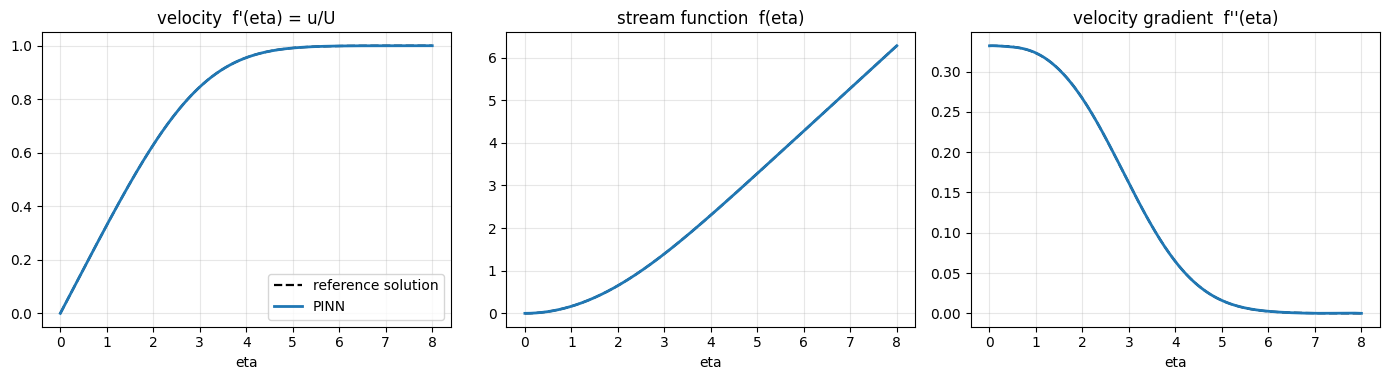

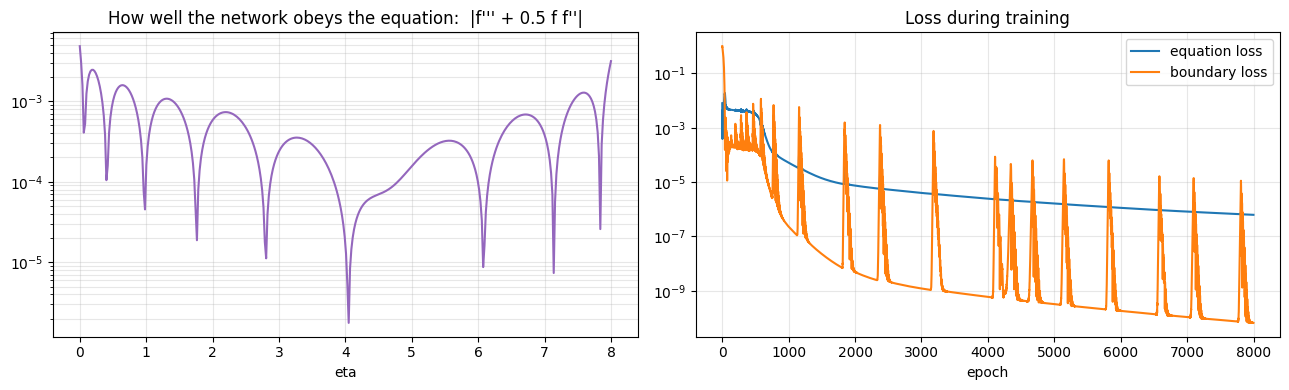

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, net, exact, title in ((axes[0], f1_a, f1_exact, "velocity  f'(eta) = u/U"),
                              (axes[1], f_a, f_exact, "stream function  f(eta)"),
                              (axes[2], f2_a, f2_exact, "velocity gradient  f''(eta)")):
    ax.plot(eta_grid, exact, "k--", lw=1.6, label="reference solution")
    ax.plot(eta_grid, net, color="tab:blue", lw=2, label="PINN")
    ax.set_title(title)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
residual_a = (f3_a + 0.5 * f_a * f2_a).ravel()
axes[0].semilogy(eta_grid, np.abs(residual_a), color="tab:purple")
axes[0].set_title("How well the network obeys the equation:  |f''' + 0.5 f f''|")
axes[0].set_xlabel("eta")
axes[0].grid(alpha=0.3, which="both")
axes[1].semilogy(hist_a[:, 1], label="equation loss")
axes[1].semilogy(hist_a[:, 2], label="boundary loss")
axes[1].set_title("Loss during training")
axes[1].set_xlabel("epoch")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

**What to notice.** The network matches the reference profile closely, and it reproduces the number that sets the drag, the wall slope, to about three decimal places. The momentum check (3) can be read straight from the table: the "momentum integral" row should match the "2 f''(0)" row. Notice that the check needed no reference solution, only the network.

The residual plot shows how well the equation is obeyed at every point, including those between the 200 collocation points.

## A8. The boundary layer, as the network sees it
The same map as in the Setup section, but built from the network's profile. The right-hand panel shows the absolute difference between this map and the one made from the reference solution.

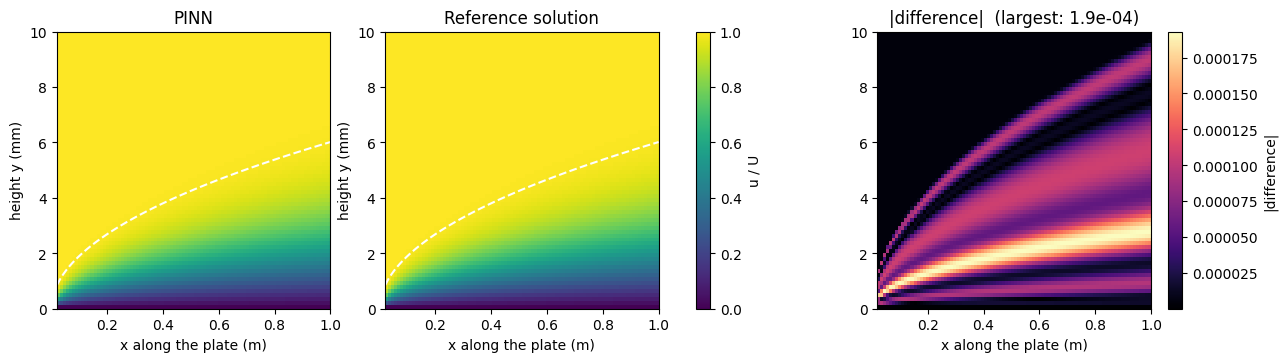

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
img0 = draw_flow_map(axes[0], f1_a, "PINN")
img1 = draw_flow_map(axes[1], f1_exact, "Reference solution")
diff = np.abs(flow_map(f1_a) - flow_map(f1_exact))
img2 = axes[2].imshow(diff, origin="lower", aspect="auto", cmap="magma",
                      extent=[MAP_X[0], MAP_X[-1], MAP_Y_MM[0], MAP_Y_MM[-1]])
axes[2].set_title(f"|difference|  (largest: {diff.max():.1e})")
axes[2].set_xlabel("x along the plate (m)")
fig.colorbar(img0, ax=axes[:2], label="u / U")
fig.colorbar(img2, ax=axes[2], label="|difference|")
plt.show()

## A9. Does it always work? A survey of random starts

One run succeeded. A fair test of a method is to repeat it with different random starting weights. We train six networks with seeds 0 to 5 and 4000 epochs each (shorter than the main run, to keep the survey quick) and call a run **solved** if its wall slope lands within 2% of the exact value.

In [15]:
survey = []
for seed in range(6):
    p, _, _ = train(seed=seed, epochs=4000, verbose=False)
    _, f1_s, _, _, wall_s = network_on_grid(p)
    ok = abs(wall_s - wall_slope_exact) / wall_slope_exact < 0.02
    survey.append((seed, wall_s, rmse(f1_s, f1_exact), ok))

print(f"{'seed':>5s}{'wall slope':>12s}{'RMSE of profile':>18s}   result")
for seed, wall_s, err, ok in survey:
    print(f"{seed:5d}{wall_s:12.4f}{err:18.2e}   {'solved' if ok else 'STUCK'}")
print(f"\nsolved: {sum(s[3] for s in survey)} of {len(survey)}   (exact wall slope = {wall_slope_exact:.4f})")

 seed  wall slope   RMSE of profile   result
    0      0.3319          4.40e-04   solved
    1      0.3320          2.35e-04   solved
    2     -0.1232          8.35e-01   STUCK
    3      0.3317          5.05e-04   solved
    4     -0.1296          8.78e-01   STUCK
    5      0.3317          5.96e-04   solved

solved: 4 of 6   (exact wall slope = 0.3321)


In this survey, 4 of 6 random starts solved the problem. Seeds 2 and 4 got stuck: their wall slopes are negative (about $-0.12$ to $-0.13$, instead of $+0.33$) and their profile errors are 0.8 to 0.9, around two thousand times larger than for the solved runs. This is the trap from section 11. Which seeds get stuck depends on the network size and the settings, so do not read "2 out of 6" as a general failure rate. Let us look at one stuck run, then fix it.

## A10. The fix: a warm start. Cold start vs warm start, side by side

We pick **seed 2** and train it twice, with the same equation, the same network and the same collocation points:

* **Cold start:** random weights, as in A7.
* **Warm start:** the same random weights, but with a 500-epoch warm-up on the rough guess from A6 first.

Both are trained for 8000 epochs and snapshots are saved for the video. (The warm-up epochs are not counted in the epoch numbers.)

In [16]:
snap_epochs = make_snapshot_epochs(8000)

print("=== cold start, seed 2 ===")
params_cold, hist_cold, snaps_cold = train(seed=2, epochs=8000, snapshot_epochs=snap_epochs)

print("\n=== warm start, seed 2 ===")
params_warm, hist_warm, snaps_warm = train(seed=2, epochs=8000, warmup_epochs=500, snapshot_epochs=snap_epochs)

=== cold start, seed 2 ===
epoch   1000/8000  total = 2.291e-03  equation = 2.248e-03  boundary = 4.360e-05  f''(0) = -0.10731
epoch   2000/8000  total = 1.977e-03  equation = 1.948e-03  boundary = 2.882e-05  f''(0) = -0.11883
epoch   3000/8000  total = 1.908e-03  equation = 1.892e-03  boundary = 1.548e-05  f''(0) = -0.12280
epoch   4000/8000  total = 1.855e-03  equation = 1.832e-03  boundary = 2.291e-05  f''(0) = -0.12720
epoch   5000/8000  total = 1.839e-03  equation = 1.817e-03  boundary = 2.183e-05  f''(0) = -0.12947
epoch   6000/8000  total = 1.831e-03  equation = 1.810e-03  boundary = 2.118e-05  f''(0) = -0.13103
epoch   7000/8000  total = 1.827e-03  equation = 1.806e-03  boundary = 2.078e-05  f''(0) = -0.13212
epoch   8000/8000  total = 1.825e-03  equation = 1.805e-03  boundary = 2.052e-05  f''(0) = -0.13288

=== warm start, seed 2 ===
epoch   1000/8000  total = 1.183e-04  equation = 1.180e-04  boundary = 3.259e-07  f''(0) = 0.32981
epoch   2000/8000  total = 1.293e-05  equation

In [17]:
rows = []
for label, params in (("cold start, seed 2", params_cold), ("warm start, seed 2", params_warm), ("cold start, seed 0 (A7)", params_a)):
    f, f1, f2, f3, wall = network_on_grid(params)
    nums = boundary_layer_numbers(eta_grid, f1, wall)
    rows.append((label, wall, rmse(f1, f1_exact), nums["momentum integral"], nums["2 f''(0)  (momentum check)"]))

print(f"{'':26s}{'wall slope':>11s}{'RMSE f-prime':>14s}{'momentum int.':>15s}{'2 x wall slope':>15s}")
for label, wall, err, mom, two_wall in rows:
    print(f"{label:26s}{wall:11.4f}{err:14.2e}{mom:15.4f}{two_wall:15.4f}")
print(f"{'exact':26s}{wall_slope_exact:11.4f}{0:14.2e}{ref_numbers['momentum integral']:15.4f}{2*wall_slope_exact:15.4f}")

                           wall slope  RMSE f-prime  momentum int. 2 x wall slope
cold start, seed 2            -0.1329      8.98e-01        -1.0685        -0.2658
warm start, seed 2             0.3321      9.38e-05         0.6643         0.6643
cold start, seed 0 (A7)        0.3321      8.83e-05         0.6645         0.6642
exact                          0.3321      0.00e+00         0.6641         0.6641


Look at the last two columns. For the stuck network the momentum check (3) fails badly: the momentum integral and $2\hat f''(0)$ disagree. We can tell that this solution is wrong **without knowing the right answer**, which is useful in real work.

### The training video and GIF

Now the animation. Left: the cold start. Right: the warm start. For each network there are three things:

1. the velocity profile against the exact one (top),
2. the boundary-layer map of $u/U$ over the plate built from the network's current profile, with the exact edge of the layer as a white dashed line (middle),
3. a strip showing the network's wall slope $\hat f''(0)$ against the exact value as training goes on (bottom).

`make_training_video` writes a GIF (always works) and an MP4 (needs `ffmpeg`).

In [ ]:
runs_video = [
    {"name": "Cold start (random weights)", "color": "tab:red", "f1": snaps_cold["f1"], "wall": snaps_cold["wall"]},
    {"name": "Warm start (rough guess first)", "color": "tab:blue", "f1": snaps_warm["f1"], "wall": snaps_warm["wall"]},
]
gif_path = MEDIA_DIR / "blasius_training.gif"
mp4_path = MEDIA_DIR / "blasius_training.mp4"

anim = make_training_video(snap_epochs, runs_video, mp4_path=mp4_path, gif_path=gif_path, fps=12)

saved GIF: media/blasius_training.gif  (1.8 MB)
saved MP4: media/blasius_training.mp4  (1.0 MB)


In [ ]:
# optional: build a GIF from the MP4 with ffmpeg (a colour palette is computed for cleaner colours)
convert_mp4_to_gif(mp4_path, MEDIA_DIR / "blasius_training_from_mp4.gif", fps=12, width=800)

converted media/blasius_training.mp4 -> media/blasius_training_from_mp4.gif  (1.6 MB)


PosixPath('media/blasius_training_from_mp4.gif')

Here is the GIF. (In Jupyter it plays inline. Elsewhere, open the file in the `media` folder.)

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(gif_path)))

**Result (GIF)**

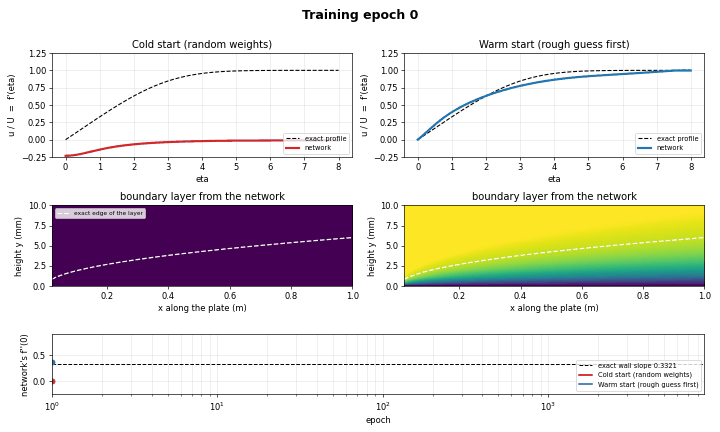

A still picture of a few moments, for places where animations do not play:

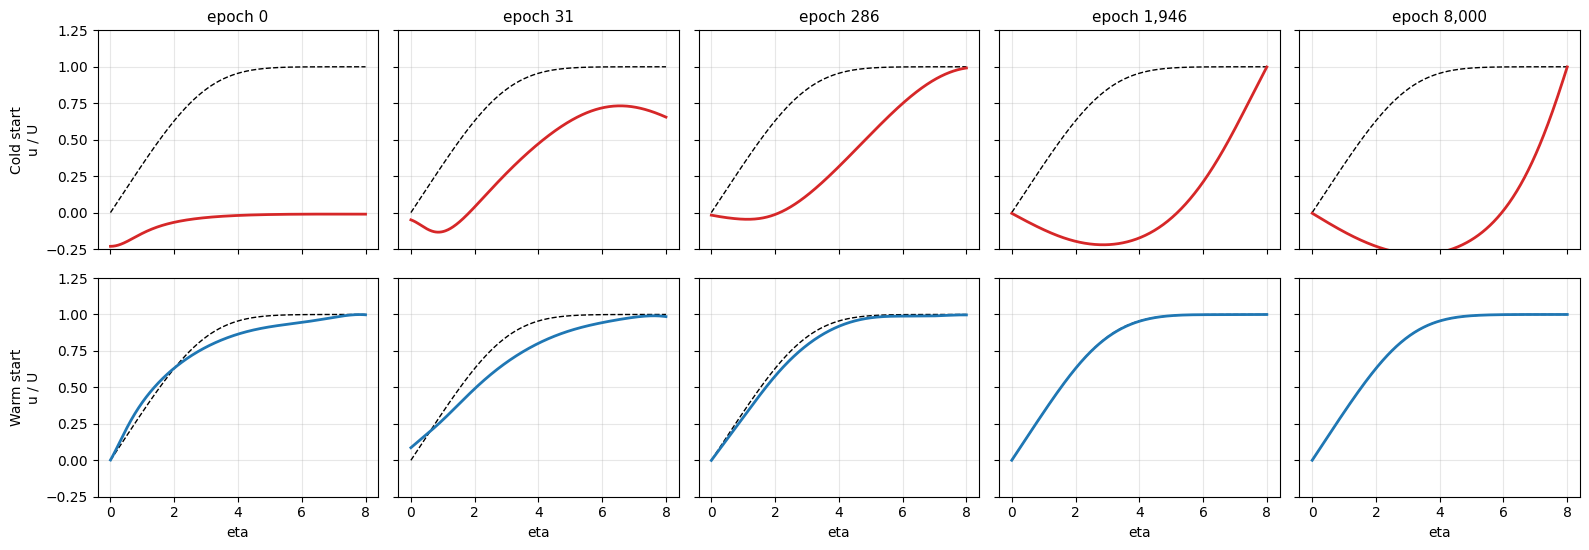

In [ ]:
snapshot_grid(snap_epochs, runs_video, picks=(0, 30, 300, 2000, 8000))

And a slider to move through training by hand (Jupyter or Colab):

In [ ]:
scrub_epochs(snap_epochs, runs_video)

interactive(children=(SelectionSlider(description='epoch', layout=Layout(width='85%'), options=(('0', 0), ('1'…

## A10b. Extension: building the wall conditions into the network
*This section goes beyond the main experiment.*

Until now the two wall conditions, $f(0)=0$ and $f'(0)=0$, were enforced with penalty terms in the loss. A different approach is to change the network's output so that they hold exactly, whatever the weights are. Write
$$\hat f(\eta)=\eta^{2}\,N(\eta),$$
where $N$ is the same network as before. Then $\hat f(0)=0$ and $\hat f'(0)=0$ automatically, and only the far-field condition is left in the loss.

The derivatives of $\hat f$ follow from the product rule (the general rule is $(\eta^2N)^{(k)}=\eta^2N^{(k)}+2k\,\eta\,N^{(k-1)}+k(k-1)\,N^{(k-2)}$):
$$\hat f=\eta^2N,\quad \hat f'=2\eta N+\eta^2N',\quad \hat f''=2N+4\eta N'+\eta^2N'',\quad \hat f'''=6N'+6\eta N''+\eta^2N'''.$$
For backpropagation, the gradients at $\hat f,\hat f',\hat f'',\hat f'''$ (call them $g_X,g_{X1},g_{X2},g_{X3}$) are turned into gradients at $N,N',N'',N'''$ by the transposed relations:
$$g_N=\eta^2g_X+2\eta\,g_{X1}+2g_{X2},\quad g_{N'}=\eta^2g_{X1}+4\eta\,g_{X2}+6g_{X3},\quad g_{N''}=\eta^2g_{X2}+6\eta\,g_{X3},\quad g_{N'''}=\eta^2g_{X3}.$$
After that, the existing `backward_jets` from A3 does the rest, unchanged. The wall slope is $\hat f''(0)=2N(0)$.

In [18]:
def hard_jets(params, eta):
    # f = eta^2 * N(eta): value and three derivatives from the network's jets (product rule)
    N0, N1, N2, N3, caches = forward_jets(params, eta)
    e = eta
    X = e**2 * N0
    X1 = 2.0 * e * N0 + e**2 * N1
    X2 = 2.0 * N0 + 4.0 * e * N1 + e**2 * N2
    X3 = 6.0 * N1 + 6.0 * e * N2 + e**2 * N3
    return X, X1, X2, X3, caches


def loss_and_grads_hard(params, batch, lam):
    # same as loss_and_grads, but the network output is f = eta^2 * N(eta)
    lam_ode, lam_bc, lam_data = lam
    no, nd = batch["n_ode"], batch["n_data"]
    i_far, i_data = no + 1, no + 2              # the wall point (index no) is no longer needed
    e = batch["eta"]
    X, X1, X2, X3, caches = hard_jets(params, e)

    r_ode = X3[:no] + 0.5 * X[:no] * X2[:no]
    b_far = X1[i_far:i_far + 1] - 1.0           # the only boundary condition left in the loss
    l_ode = np.mean(r_ode**2)
    l_bc = np.mean(b_far**2)
    total = lam_ode * l_ode + lam_bc * l_bc

    gX, gX1, gX2, gX3 = (np.zeros_like(X) for _ in range(4))
    g_res = lam_ode * 2.0 / no * r_ode
    gX[:no] += g_res * 0.5 * X2[:no]
    gX2[:no] += g_res * 0.5 * X[:no]
    gX3[:no] += g_res
    gX1[i_far:i_far + 1] += lam_bc * 2.0 * b_far

    l_data = 0.0
    if nd:
        r_data = X1[i_data:i_data + nd] - batch["f1_data"]
        l_data = np.mean(r_data**2)
        total += lam_data * l_data
        gX1[i_data:i_data + nd] += lam_data * 2.0 / nd * r_data

    # map the gradients back to the network's own value and derivatives
    gN0 = e**2 * gX + 2.0 * e * gX1 + 2.0 * gX2
    gN1 = e**2 * gX1 + 4.0 * e * gX2 + 6.0 * gX3
    gN2 = e**2 * gX2 + 6.0 * e * gX3
    gN3 = e**2 * gX3
    grads = backward_jets(params, caches, gN0, gN1, gN2, gN3)
    return total, (l_ode, l_bc, l_data), grads

The same finite-difference test as in A4, now for the new loss. A result of a few parts in a million or smaller means the mapping is right.

In [19]:
# finite-difference check of the new gradients (reuses the small test case from A4)
_, _, analytic_h = loss_and_grads_hard(test_params, test_batch, test_lam)

eps = 1e-6
worst_h = 0.0
for name in analytic_h:
    numeric = np.zeros_like(test_params[name])
    it = np.nditer(test_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = test_params[name][idx]
        test_params[name][idx] = old + eps
        up = loss_and_grads_hard(test_params, test_batch, test_lam)[0]
        test_params[name][idx] = old - eps
        down = loss_and_grads_hard(test_params, test_batch, test_lam)[0]
        test_params[name][idx] = old
        numeric[idx] = (up - down) / (2 * eps)
    denom = np.maximum(np.abs(numeric) + np.abs(analytic_h[name]), 1e-12)
    worst_h = max(worst_h, np.max(np.abs(numeric - analytic_h[name]) / denom))
print(f"worst relative difference over all weights: {worst_h:.2e}")

worst relative difference over all weights: 1.93e-06


Now we train this version with random starting weights (cold start) and with the 500-epoch warm-up from A6 (warm start), for seeds 0, 1 and 2, 8000 epochs each, with the same settings as before. The warm-up uses the same rough guess for $f'$. The next two cells take about five minutes in total.

In [20]:
def warm_up_hard(params, epochs=500, n_points=200, lr=3e-3):
    eta_w = np.linspace(0.0, ETA_MAX, n_points).reshape(-1, 1)
    batch = make_batch(eta_w, eta_w, guess_profile(eta_w))
    opt = Adam(params)
    for _ in range(epochs):
        _, _, grads = loss_and_grads_hard(params, batch, (0.0, 1.0, 1.0))
        opt.step(params, grads, lr)


def train_hard(seed=0, epochs=8000, sizes=SIZES, n_colloc=200, warmup_epochs=0):
    params = init_params(sizes, seed=seed)
    if warmup_epochs > 0:
        warm_up_hard(params, warmup_epochs)
    batch = make_batch(np.linspace(0.0, ETA_MAX, n_colloc).reshape(-1, 1))
    opt = Adam(params)
    for epoch in range(epochs):
        total, _, grads = loss_and_grads_hard(params, batch, (1.0, 1.0, 0.0))
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(params, grads, lr)
    return params, total


def hard_profile(params):
    X, X1, X2, X3, _ = hard_jets(params, eta_grid)
    wall = 2.0 * forward_jets(params, np.zeros((1, 1)))[0].item()      # f''(0) = 2 N(0)
    return X1, wall

             seed  wall slope  RMSE f-prime  final loss   result
cold start      0     -0.1296      8.41e-01    2.61e-03   STUCK
cold start      1     -0.1264      8.25e-01    2.70e-03   STUCK
cold start      2      0.3312      9.43e-04    1.99e-05   solved
warm start      0      0.3313      2.06e-03    3.59e-05   solved
warm start      1      0.3328      1.24e-03    2.10e-05   solved
warm start      2      0.3325      2.97e-04    6.14e-06   solved
exact                  0.3321


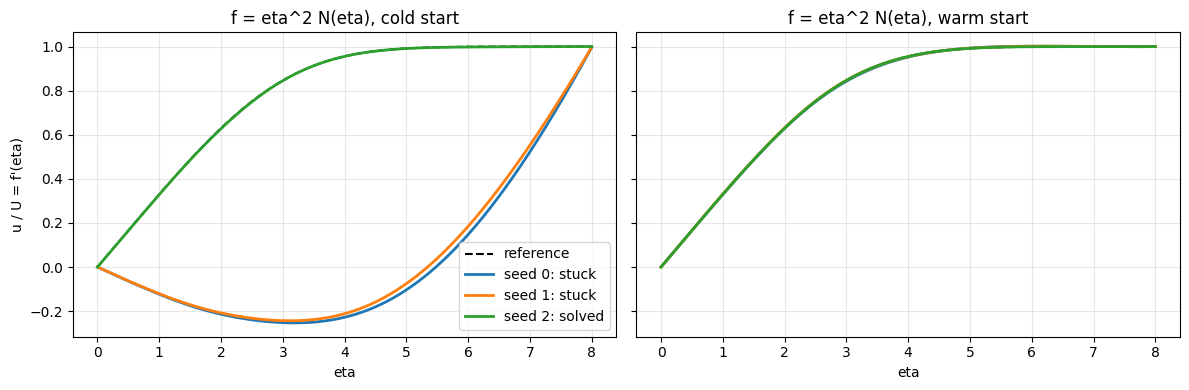

In [21]:
hard_results = []
for warm_epochs, label in ((0, "cold start"), (500, "warm start")):
    for seed in (0, 1, 2):
        p, final_loss = train_hard(seed=seed, warmup_epochs=warm_epochs)
        f1_h, wall_h = hard_profile(p)
        solved = abs(wall_h - wall_slope_exact) / wall_slope_exact < 0.02
        hard_results.append((label, seed, wall_h, rmse(f1_h, f1_exact), final_loss, solved, f1_h))

print(f"{'':12s}{'seed':>5s}{'wall slope':>12s}{'RMSE f-prime':>14s}{'final loss':>12s}   result")
for label, seed, wall_h, err, final_loss, solved, _ in hard_results:
    print(f"{label:12s}{seed:5d}{wall_h:12.4f}{err:14.2e}{final_loss:12.2e}   {'solved' if solved else 'STUCK'}")
print(f"{'exact':12s}{'':5s}{wall_slope_exact:12.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, label in zip(axes, ("cold start", "warm start")):
    ax.plot(eta_grid, f1_exact, "k--", lw=1.5, label="reference")
    for lab, seed, wall_h, err, final_loss, solved, f1_h in hard_results:
        if lab == label:
            ax.plot(eta_grid, f1_h, lw=2, label=f"seed {seed}: {'solved' if solved else 'stuck'}")
    ax.set_title(f"f = eta^2 N(eta), {label}")
    ax.set_xlabel("eta")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("u / U = f'(eta)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

## A11. The inverse problem: wall friction from noisy readings in NumPy

Now we use the measurements from S8: 14 noisy readings of $u/U$ between 0.6 and 6 mm, none closer to the wall. The scale $\kappa$ is unknown. We start with a guess of 0.7 per millimetre (the truth is 1.155) and train the network and $\kappa$ together on the equation, the boundary conditions and the data (background section 12). A warm-up comes first, as in A10.

For comparison, the classical approach: fit a cubic polynomial through the readings and extend it to the wall.

In [ ]:
def train_inverse(seed=0, epochs=10000, sizes=(1, 24, 24, 24, 1), n_colloc=120, kappa_start=0.7,
                  lam=(1.0, 1.0, 1.0), warmup_epochs=500, verbose=True, print_every=2000):
    params = init_params(sizes, seed=seed)
    if warmup_epochs > 0:
        warm_up(params, warmup_epochs)
    trainable = dict(params)
    trainable["kappa"] = np.array([kappa_start])           # the unknown scale, per millimetre
    opt = Adam(trainable)
    eta_ode = np.linspace(0.0, ETA_MAX, n_colloc).reshape(-1, 1)

    kappa_history = []
    for epoch in range(epochs):
        kappa = float(trainable["kappa"][0])
        batch = make_batch(eta_ode, kappa * y_meas, u_meas)       # the measurement points move with kappa
        total, parts, grads, aux = loss_and_grads(params, batch, lam, want_aux=True)
        # extra gradient for kappa (background section 12): mean of 2 r y f''
        grads["kappa"] = np.array([lam[2] * np.mean(2.0 * aux["r_data"] * y_meas * aux["f2_data"])])
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(trainable, grads, lr)
        kappa_history.append(kappa)
        if verbose and (epoch + 1) % print_every == 0:
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total:.3e}  kappa = {kappa:.4f}  (true {kappa_true:.4f})")
    return params, float(trainable["kappa"][0]), np.array(kappa_history)


params_inv, kappa_hat, kappa_hist = train_inverse()

epoch   2000/10000  total = 7.506e-04  kappa = 1.1109  (true 1.1547)
epoch   4000/10000  total = 7.393e-04  kappa = 1.1144  (true 1.1547)
epoch   6000/10000  total = 7.370e-04  kappa = 1.1141  (true 1.1547)
epoch   8000/10000  total = 7.356e-04  kappa = 1.1143  (true 1.1547)
epoch  10000/10000  total = 7.348e-04  kappa = 1.1146  (true 1.1547)


In [ ]:
f_i, f1_i, f2_i, f3_i, wall_i = network_on_grid(params_inv)
eta99_i = boundary_layer_numbers(eta_grid, f1_i, wall_i)["eta_99"]

# classical baseline: cubic polynomial through the readings, slope at y = 0
coef = np.polyfit(y_meas.ravel(), u_meas.ravel(), 3)
poly_slope_per_mm = coef[2]                                        # d(u/U)/dy at the wall, per mm

rate_true = U_inf * kappa_true * 1000.0 * wall_slope_exact         # wall velocity gradient (1/s)
rate_pinn = U_inf * kappa_hat * 1000.0 * wall_i
rate_poly = U_inf * poly_slope_per_mm * 1000.0

print(f"{'':34s}{'estimate':>12s}{'truth':>12s}{'error':>10s}")
print(f"{'scale kappa (per mm), PINN':34s}{kappa_hat:12.4f}{kappa_true:12.4f}{100*(kappa_hat/kappa_true-1):9.1f}%")
print(f"{'delta_99 (mm), PINN':34s}{eta99_i/kappa_hat:12.3f}{ref_numbers['eta_99']/kappa_true:12.3f}"
      f"{100*((eta99_i/kappa_hat)/(ref_numbers['eta_99']/kappa_true)-1):9.1f}%")
print(f"{'wall velocity gradient (1/s), PINN':34s}{rate_pinn:12.0f}{rate_true:12.0f}{100*(rate_pinn/rate_true-1):9.1f}%")
print(f"{'wall velocity gradient (1/s), cubic':34s}{rate_poly:12.0f}{rate_true:12.0f}{100*(rate_poly/rate_true-1):9.1f}%")

                                      estimate       truth     error
scale kappa (per mm), PINN              1.1146      1.1547     -3.5%
delta_99 (mm), PINN                      4.190       4.252     -1.5%
wall velocity gradient (1/s), PINN        3768        3834     -1.7%
wall velocity gradient (1/s), cubic        4839        3834     26.2%


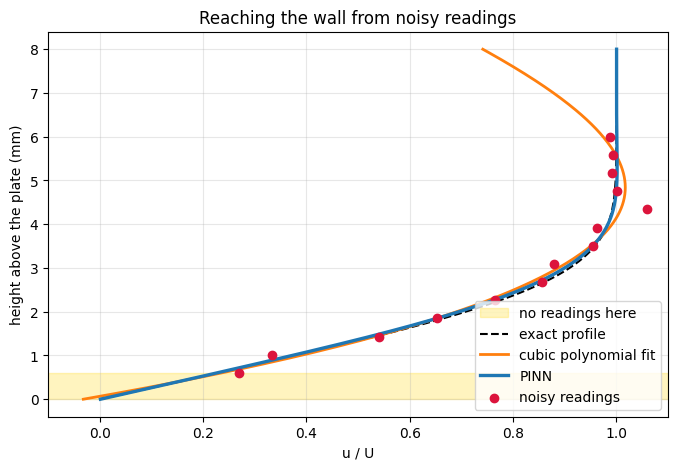

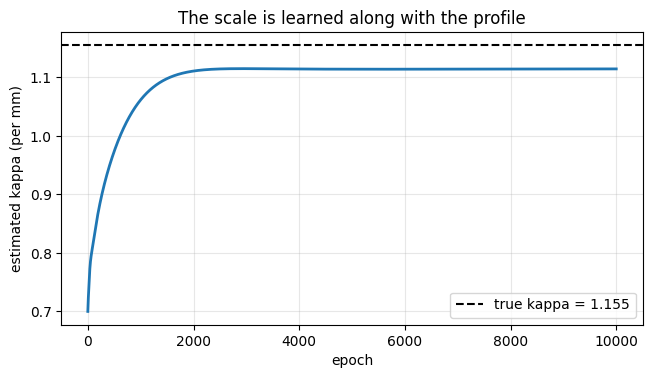

In [ ]:
y_plot = np.linspace(0, 8, 300)
plt.figure(figsize=(8, 5))
plt.axhspan(0, 0.6, color="gold", alpha=0.25, label="no readings here")
plt.plot(ref(kappa_true * y_plot)[1], y_plot, "k--", label="exact profile")
plt.plot(np.polyval(coef, y_plot), y_plot, color="tab:orange", lw=2, label="cubic polynomial fit")
plt.plot(np.interp(kappa_hat * y_plot, eta_grid.ravel(), f1_i.ravel()), y_plot, color="tab:blue", lw=2.4, label="PINN")
plt.scatter(u_meas, y_meas, color="crimson", zorder=3, label="noisy readings")
plt.xlim(-0.1, 1.1)
plt.xlabel("u / U")
plt.ylabel("height above the plate (mm)")
plt.title("Reaching the wall from noisy readings")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7.5, 3.8))
plt.plot(kappa_hist, lw=2)
plt.axhline(kappa_true, color="k", ls="--", label=f"true kappa = {kappa_true:.3f}")
plt.xlabel("epoch")
plt.ylabel("estimated kappa (per mm)")
plt.title("The scale is learned along with the profile")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The plain polynomial does fine where there are readings but has no idea what happens below 0.6 mm, so its wall gradient is badly off. The PINN gets the near-wall behaviour from the equation, so its estimate is much closer.

**Is that just luck with one noise sample?** The noise in the readings is random. Below we repeat the experiment 300 times with new noise each time. To keep it fast we use the profile that the network learned in A7 and only fit $\kappa$ to each noisy set (a one-number least-squares fit). The polynomial is refit every time. This tells us the typical size of the errors.

wall-gradient error over 300 noise draws:
  PINN profile fit : mean    0.1%   spread (std)   1.7%
  cubic polynomial : mean   53.8%   spread (std)  11.1%


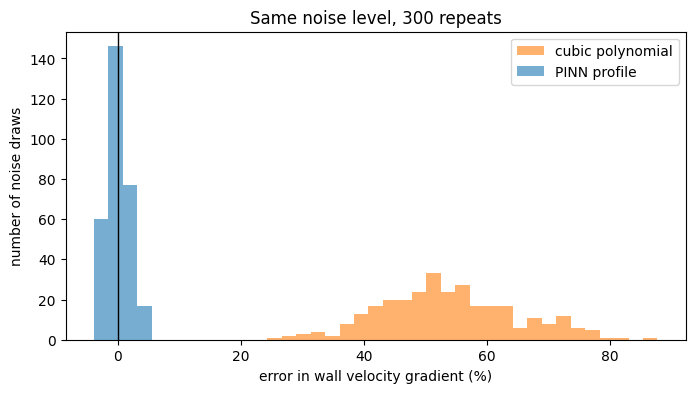

In [ ]:
from scipy.optimize import minimize_scalar

profile_net = f1_a.ravel()               # the profile learned in A7
n_draws = 300
rng_mc = np.random.default_rng(11)
err_pinn, err_poly = [], []
for _ in range(n_draws):
    u_noisy = ref(kappa_true * y_meas)[1] + noise_level * rng_mc.standard_normal(y_meas.shape)
    fit = minimize_scalar(lambda k: np.mean((np.interp(k * y_meas, eta_grid.ravel(), profile_net) - u_noisy) ** 2),
                          bounds=(0.3, 2.5), method="bounded")
    err_pinn.append(100 * (fit.x * wall_a / (kappa_true * wall_slope_exact) - 1))
    c3 = np.polyfit(y_meas.ravel(), u_noisy.ravel(), 3)
    err_poly.append(100 * (c3[2] / (kappa_true * wall_slope_exact) - 1))

print(f"wall-gradient error over {n_draws} noise draws:")
print(f"  PINN profile fit : mean {np.mean(err_pinn):6.1f}%   spread (std) {np.std(err_pinn):5.1f}%")
print(f"  cubic polynomial : mean {np.mean(err_poly):6.1f}%   spread (std) {np.std(err_poly):5.1f}%")

plt.figure(figsize=(8, 4))
bins = np.linspace(min(min(err_pinn), min(err_poly)), max(max(err_pinn), max(err_poly)), 40)
plt.hist(err_poly, bins=bins, alpha=0.6, color="tab:orange", label="cubic polynomial")
plt.hist(err_pinn, bins=bins, alpha=0.6, color="tab:blue", label="PINN profile")
plt.axvline(0, color="k", lw=1)
plt.xlabel("error in wall velocity gradient (%)")
plt.ylabel("number of noise draws")
plt.title("Same noise level, 300 repeats")
plt.legend()
plt.show()

In these 300 repeats, the PINN-profile estimate of the wall gradient is on target on average (mean error close to 0%) with a spread of about 2%. The cubic polynomial is typically more than 50% too high, with a spread of about 11%. The polynomial's trouble is not noise alone: it has to extend into a region with no readings, and a cubic is not shaped like the real profile there. One caveat: the PINN-side repeats reuse the profile learned in A7 and only refit $\kappa$, so they show how much noise moves the fitted scale, and not how much it would move a full retraining.

**End of Part A.** Everything above used NumPy only: a network that returns three derivatives of itself, hand-derived gradients tested against finite differences, an optimiser, a survey that exposed a real failure mode, a warm start that cured it, a training video, and an inverse problem. In Part B the derivative work is done automatically by PyTorch.

---
---
# Part B: PyTorch and more advanced tools

The problem is the same: solve $f'''+\tfrac12ff''=0$ with $f(0)=f'(0)=0$ and $f'(\eta_{\max})=1$. What changes is who does the calculus.

1. **Automatic differentiation** gives $\hat f'$, $\hat f''$ and $\hat f'''$. We call PyTorch's `autograd.grad` three times and never write the formulas of background section 10.
2. **Backpropagation** through the whole loss, including all three derivatives, is one call to `loss.backward()`. The long derivation in A3 collapses into a single line.

The first half (B1 to B8) rebuilds the experiment, the random-start survey, the warm-start fix and the video in PyTorch. The second half (B9 to B12) adds: L-BFGS polishing, `torch.func`, an inverse problem with a trainable constant, and wedge flows (Falkner–Skan), where the same network handles flows with a pressure gradient.

> **Setup needed.** Part B needs PyTorch (`pip install torch`; Colab has it). Run the **Setup** section first, since the constants, reference solution, measurements and helper functions come from there.
>
> **Runtime.** Differentiating three times is slower than a plain forward pass. As a rough guide, the whole of Part B takes somewhere around 15 to 25 minutes on a laptop CPU.
>
> **A note on random seeds.** PyTorch draws different random numbers from NumPy, so seed 2 in this part is *not* the same network as seed 2 in Part A. Which random starts get stuck can differ between the two parts. B7 therefore looks for a stuck seed itself.

## B1. Imports and random seed

In [ ]:
import copy
import torch
import torch.nn as nn

torch.manual_seed(0)

## B2. Tensors
The collocation points, the plotting grid and the measurements from Setup, as `float32` tensors (one row per point).

In [ ]:
eta_colloc_t = torch.linspace(0.0, ETA_MAX, 200).reshape(-1, 1)           # where the equation is checked
eta_grid_t = torch.tensor(eta_grid, dtype=torch.float32)                  # plotting grid
y_meas_t = torch.tensor(y_meas, dtype=torch.float32)                      # measurement heights (mm)
u_meas_t = torch.tensor(u_meas, dtype=torch.float32)                      # measured u/U

print(eta_colloc_t.shape, eta_grid_t.shape, y_meas_t.shape)

torch.Size([200, 1]) torch.Size([400, 1]) torch.Size([14, 1])


## B3. The network
The same shape as in Part A: 1 → 32 → 32 → 32 → 1 with $\tanh$, Xavier-uniform weights and zero biases (the random numbers differ from NumPy's).

In [ ]:
class PINN(nn.Module):
    def __init__(self, hidden=(32, 32, 32)):
        super().__init__()
        sizes = [1, *hidden, 1]
        layers = []
        for i in range(len(sizes) - 1):
            linear = nn.Linear(sizes[i], sizes[i + 1])
            nn.init.xavier_uniform_(linear.weight)
            nn.init.zeros_(linear.bias)
            layers.append(linear)
            if i < len(sizes) - 2:
                layers.append(nn.Tanh())
        self.net = nn.Sequential(*layers)

    def forward(self, eta):
        # input (N, 1) -> output (N, 1)
        return self.net(eta)

## B4. Differentiating with autograd
`torch.autograd.grad(y, x, ...)` returns $\partial y/\partial x$ for every entry. Passing `grad_outputs=torch.ones_like(y)` asks for each entry's derivative with respect to its own input. `create_graph=True` keeps a record of how the derivative was computed, which is needed (a) to differentiate again, for the second and third derivatives, and (b) to differentiate the loss with respect to the weights afterwards.

Calling the helper three times in a row gives $\hat f'$, $\hat f''$ and $\hat f'''$.

In [ ]:
def derivative(y, x):
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

## B5. The loss terms
`ode_loss` switches on gradient tracking for the points, gets the three derivatives by calling `derivative` three times, and forms the residual. It has two extra arguments, `a` and `m_fs`, which are 0.5 and 0 for the Blasius equation. They let us reuse the same function for wedge flows in B12, where the equation becomes $f'''+a\,ff''+m(1-f'^2)=0$. `bc_loss` is the three boundary conditions.

In [ ]:
def ode_loss(model, eta, a=0.5, m_fs=0.0):
    eta = eta.clone().requires_grad_(True)
    f = model(eta)
    f1 = derivative(f, eta)
    f2 = derivative(f1, eta)
    f3 = derivative(f2, eta)
    residual = f3 + a * f * f2 + m_fs * (1.0 - f1 ** 2)
    return torch.mean(residual ** 2)


def bc_loss(model):
    e0 = torch.zeros(1, 1, requires_grad=True)
    eM = torch.full((1, 1), ETA_MAX, requires_grad=True)
    f_0 = model(e0)
    f1_0 = derivative(f_0, e0)
    f_M = model(eM)
    f1_M = derivative(f_M, eM)
    return torch.mean(f_0 ** 2) + torch.mean(f1_0 ** 2) + torch.mean((f1_M - 1.0) ** 2)

## B6. Warm-up and training
The training function mirrors Part A: Adam with a learning rate falling from $3\times10^{-3}$ to $10^{-4}$ (`ExponentialLR` with factor $(\eta_1/\eta_0)^{1/K}$ per epoch), optional warm-up on the rough guess $f'\approx1-e^{-\eta/2}$, and snapshots for the video. `profile_and_wall` returns the network's $f$, $f'$, $f''$ on the plotting grid and its wall slope $\hat f''(0)$.

In [ ]:
EPOCHS = 8000
LR_START, LR_END = 3e-3, 1e-4


def profile_and_wall(model):
    eta = eta_grid_t.clone().requires_grad_(True)
    f = model(eta)
    f1 = derivative(f, eta)
    f2 = derivative(f1, eta)
    e0 = torch.zeros(1, 1, requires_grad=True)
    wall = derivative(derivative(model(e0), e0), e0).item()
    return (f.detach().numpy().ravel(), f1.detach().numpy().ravel(), f2.detach().numpy().ravel(), wall)


def warm_up_torch(model, epochs=500, lr=3e-3):
    # train the network to follow a rough guess for f' while meeting the boundary conditions
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    eta_w = eta_colloc_t.clone().requires_grad_(True)
    target = (1.0 - torch.exp(-eta_w / 2.0)).detach()
    for _ in range(epochs):
        optimizer.zero_grad()
        f = model(eta_w)
        f1 = derivative(f, eta_w)
        loss = torch.mean((f1 - target) ** 2) + bc_loss(model)
        loss.backward()
        optimizer.step()


def train_torch(seed=0, epochs=EPOCHS, warmup_epochs=0, a=0.5, m_fs=0.0,
                snapshot_epochs=None, verbose=True, print_every=1000):
    torch.manual_seed(seed)
    model = PINN()
    if warmup_epochs > 0:
        warm_up_torch(model, warmup_epochs)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_START)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=(LR_END / LR_START) ** (1.0 / epochs))
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, snap_f1, snap_wall = [], [], []
    for epoch in range(epochs + 1):
        if epoch in snap_set:
            _, f1_now, _, wall_now = profile_and_wall(model)
            snap_f1.append(f1_now)
            snap_wall.append(wall_now)
        if epoch == epochs:
            break
        optimizer.zero_grad()
        l_ode = ode_loss(model, eta_colloc_t, a, m_fs)
        l_bc = bc_loss(model)
        total = l_ode + l_bc
        total.backward()
        optimizer.step()
        scheduler.step()
        history.append([total.item(), l_ode.item(), l_bc.item()])
        if verbose and (epoch + 1) % print_every == 0:
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total.item():.3e}  equation = {l_ode.item():.3e}  "
                  f"boundary = {l_bc.item():.3e}")
    return model, np.array(history), {"f1": np.array(snap_f1), "wall": np.array(snap_wall)}

## B7. Survey of random starts, then cold vs warm
As in Part A, a PINN started from random weights can fall into the "do nothing" trap. We train six cold-start networks for 4000 epochs each and call a run solved if its wall slope is within 2% of the exact value. Then the first stuck seed we find (or seed 2, if none gets stuck) is trained twice for 8000 epochs, cold and warm, with snapshots for the video.

In [ ]:
survey_t = []
for seed in range(6):
    m_s, _, _ = train_torch(seed=seed, epochs=4000, verbose=False)
    _, f1_s, _, wall_s = profile_and_wall(m_s)
    ok = abs(wall_s - wall_slope_exact) / wall_slope_exact < 0.02
    survey_t.append((seed, wall_s, rmse(f1_s, f1_exact), ok))

print(f"{'seed':>5s}{'wall slope':>12s}{'RMSE of profile':>18s}   result")
for seed, wall_s, err, ok in survey_t:
    print(f"{seed:5d}{wall_s:12.4f}{err:18.2e}   {'solved' if ok else 'STUCK'}")
stuck = [s[0] for s in survey_t if not s[3]]
demo_seed = stuck[0] if stuck else 2
print(f"\nsolved: {sum(s[3] for s in survey_t)} of {len(survey_t)}.  Demonstration seed for the video: {demo_seed}")

 seed  wall slope   RMSE of profile   result
    0     -0.1244          8.81e-01   STUCK
    1     -0.1246          8.83e-01   STUCK
    2      0.3321          4.16e-01   solved
    3     -0.1250          8.86e-01   STUCK
    4     -0.1223          8.72e-01   STUCK
    5      0.3320          4.16e-01   solved

solved: 2 of 6.  Demonstration seed for the video: 0


In [ ]:
snap_epochs = make_snapshot_epochs(EPOCHS)

print(f"=== cold start, seed {demo_seed} ===")
model_cold, hist_cold_t, snaps_cold_t = train_torch(seed=demo_seed, snapshot_epochs=snap_epochs)

print(f"\n=== warm start, seed {demo_seed} ===")
model_warm, hist_warm_t, snaps_warm_t = train_torch(seed=demo_seed, warmup_epochs=500, snapshot_epochs=snap_epochs)

=== cold start, seed 0 ===
epoch   1000/8000  total = 2.449e-03  equation = 2.322e-03  boundary = 1.268e-04
epoch   2000/8000  total = 2.221e-03  equation = 1.861e-03  boundary = 3.601e-04
epoch   3000/8000  total = 1.887e-03  equation = 1.861e-03  boundary = 2.593e-05
epoch   4000/8000  total = 1.852e-03  equation = 1.830e-03  boundary = 2.252e-05
epoch   5000/8000  total = 1.842e-03  equation = 1.827e-03  boundary = 1.518e-05
epoch   6000/8000  total = 1.832e-03  equation = 1.811e-03  boundary = 2.107e-05
epoch   7000/8000  total = 1.829e-03  equation = 1.808e-03  boundary = 2.075e-05
epoch   8000/8000  total = 1.827e-03  equation = 1.807e-03  boundary = 2.055e-05

=== warm start, seed 0 ===
epoch   1000/8000  total = 1.929e-05  equation = 1.928e-05  boundary = 5.663e-09
epoch   2000/8000  total = 8.158e-06  equation = 8.157e-06  boundary = 8.099e-10
epoch   3000/8000  total = 4.907e-06  equation = 4.902e-06  boundary = 5.037e-09
epoch   4000/8000  total = 2.906e-06  equation = 2.905

                           wall slope  RMSE f-prime  momentum int. 2 x wall slope
cold start, seed 0            -0.1331      9.24e-01        -1.0772        -0.2662
warm start, seed 0             0.3321      4.16e-01         0.6644         0.6641
exact                          0.3321      0.00e+00         0.6641         0.6641


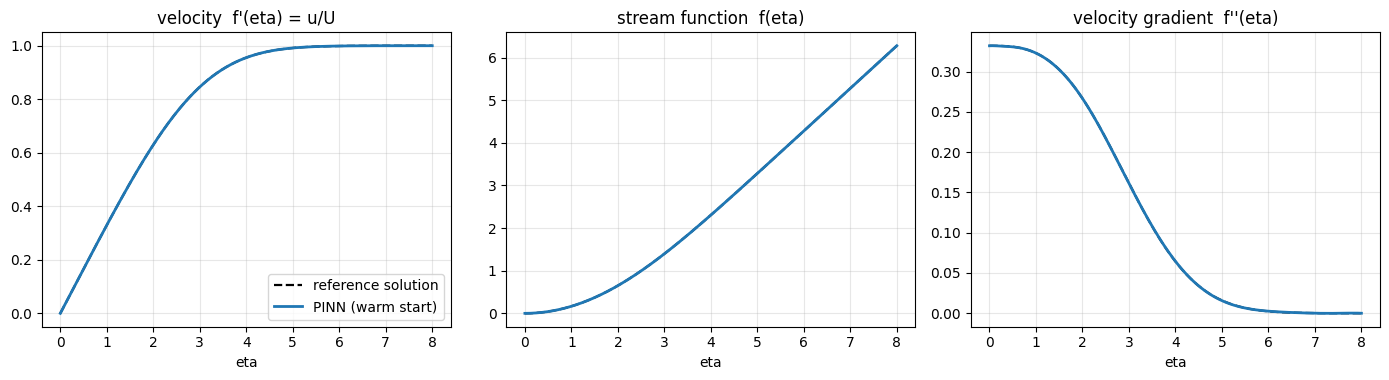

In [ ]:
print(f"{'':26s}{'wall slope':>11s}{'RMSE f-prime':>14s}{'momentum int.':>15s}{'2 x wall slope':>15s}")
for label, model in ((f"cold start, seed {demo_seed}", model_cold), (f"warm start, seed {demo_seed}", model_warm)):
    f, f1, f2, wall = profile_and_wall(model)
    nums = boundary_layer_numbers(eta_grid, f1, wall)
    print(f"{label:26s}{wall:11.4f}{rmse(f1, f1_exact):14.2e}{nums['momentum integral']:15.4f}{2*wall:15.4f}")
print(f"{'exact':26s}{wall_slope_exact:11.4f}{0:14.2e}{ref_numbers['momentum integral']:15.4f}{2*wall_slope_exact:15.4f}")

f_w, f1_w, f2_w, wall_w = profile_and_wall(model_warm)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, net, exact, title in ((axes[0], f1_w, f1_exact, "velocity  f'(eta) = u/U"),
                              (axes[1], f_w, f_exact, "stream function  f(eta)"),
                              (axes[2], f2_w, f2_exact, "velocity gradient  f''(eta)")):
    ax.plot(eta_grid, exact, "k--", lw=1.6, label="reference solution")
    ax.plot(eta_grid, net, color="tab:blue", lw=2, label="PINN (warm start)")
    ax.set_title(title)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

The pattern to look for is the one from Part A: a cold start can end at the wrong wall slope and fail the momentum check (3), while the warm start finds the right profile. If your survey shows no stuck seed, that is also a valid result: the trap depends on the random numbers, and a few runs can be lucky.

## B8. The training video again, from the PyTorch run
The same helper builds the animation. The files get a `_pytorch` suffix.

In [ ]:
runs_video_t = [
    {"name": "Cold start (random weights)", "color": "tab:red", "f1": snaps_cold_t["f1"], "wall": snaps_cold_t["wall"]},
    {"name": "Warm start (rough guess first)", "color": "tab:blue", "f1": snaps_warm_t["f1"], "wall": snaps_warm_t["wall"]},
]
gif_path_t = MEDIA_DIR / "blasius_training_pytorch.gif"
mp4_path_t = MEDIA_DIR / "blasius_training_pytorch.mp4"

anim_t = make_training_video(snap_epochs, runs_video_t, mp4_path=mp4_path_t, gif_path=gif_path_t, fps=12)

from IPython.display import Image, display
display(Image(filename=str(gif_path_t)))

**Result (GIF)**

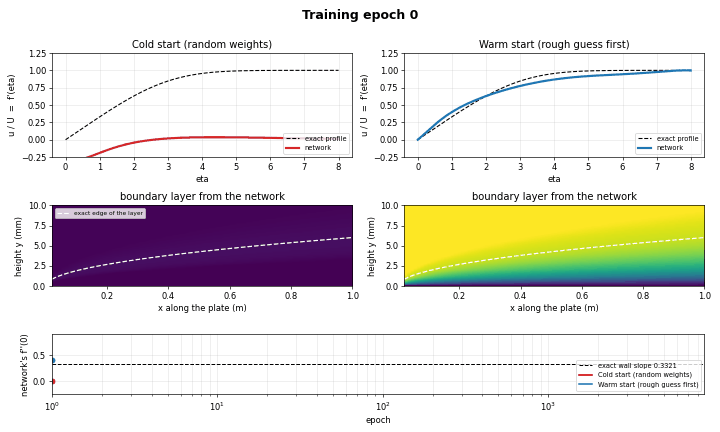

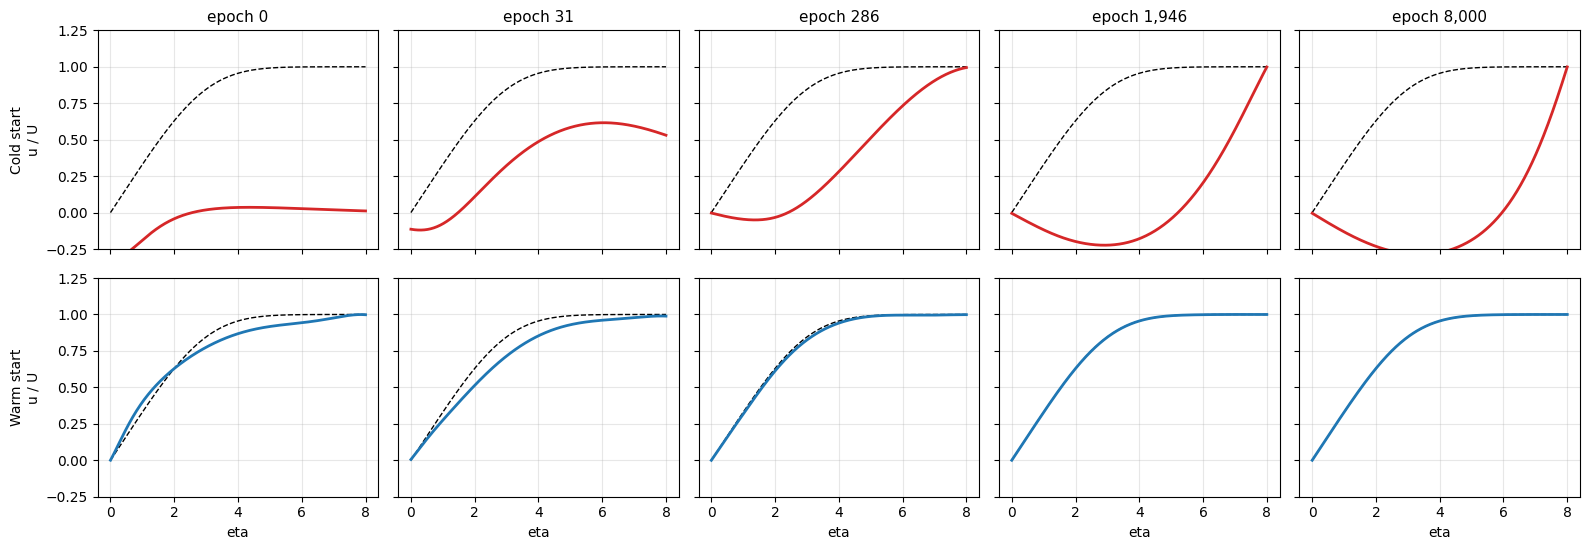

In [ ]:
snapshot_grid(snap_epochs, runs_video_t, picks=(0, 30, 300, 2000, 8000))

In [ ]:
scrub_epochs(snap_epochs, runs_video_t)

interactive(children=(SelectionSlider(description='epoch', layout=Layout(width='85%'), options=(('0', 0), ('1'…

---
## Advanced additions

Everything below goes beyond the basic experiment.

## B9. Polishing with L-BFGS
Adam is steady but slow to settle. **L-BFGS** is a quasi-Newton method that builds a rough picture of the loss surface's curvature from recent gradients and takes bigger, better-aimed steps (Liu and Nocedal, 1989). Because we are *solving an equation* with no noisy data, the loss can be driven very low, which is where L-BFGS helps most. A common PINN recipe is Adam first and L-BFGS to finish.

PyTorch's L-BFGS needs a **closure** that recomputes the loss and gradients on demand. It prefers 64-bit numbers, and our model is 32-bit, so progress can stall or occasionally give non-finite values. The cell checks for that and keeps the Adam result if it happens.

In [ ]:
model_lbfgs = copy.deepcopy(model_warm)
lbfgs = torch.optim.LBFGS(model_lbfgs.parameters(), lr=1.0, max_iter=500, history_size=50,
                          tolerance_grad=1e-12, tolerance_change=1e-15, line_search_fn="strong_wolfe")

def closure():
    lbfgs.zero_grad()
    loss = ode_loss(model_lbfgs, eta_colloc_t) + bc_loss(model_lbfgs)
    loss.backward()
    return loss

_, f1_before, _, wall_before = profile_and_wall(model_warm)
lbfgs.step(closure)
_, f1_after, _, wall_after = profile_and_wall(model_lbfgs)

if np.isfinite(f1_after).all():
    print(f"wall slope error  before L-BFGS: {abs(wall_before - wall_slope_exact):.2e}   after: {abs(wall_after - wall_slope_exact):.2e}")
    print(f"profile RMSE      before L-BFGS: {rmse(f1_before, f1_exact):.2e}   after: {rmse(f1_after, f1_exact):.2e}")
else:
    print("L-BFGS produced non-finite values in 32-bit arithmetic; keeping the Adam result.")
    model_lbfgs = model_warm

wall slope error  before L-BFGS: 2.64e-06   after: 2.12e-05
profile RMSE      before L-BFGS: 4.16e-01   after: 4.16e-01


Compare the two lines. If L-BFGS helped, both errors fall. In 32-bit arithmetic there is a floor of roughly one part in a million, and that limits how far any polishing can go.

## B10. Third derivatives with `torch.func`
In B4 we called `autograd.grad` three times. The functional interface `torch.func` works differently: write a function for a **single** point, then ask for its derivative. `jacrev(f)` returns $f'$, `jacrev(jacrev(f))` returns $f''$, and so on, and `vmap` applies the result to a whole batch. This style is common in more advanced code because it extends cleanly to several inputs and to mixed derivatives in PDEs. Here we compute $\hat f'$ and $\hat f'''$ both ways and compare.

In [ ]:
from torch.func import vmap, jacrev

def f_scalar(e):
    return model_warm(e.reshape(1, 1)).reshape(())

first = vmap(jacrev(f_scalar))
third = vmap(jacrev(jacrev(jacrev(f_scalar))))

e_check = torch.linspace(0.0, ETA_MAX, 9)
f1_func, f3_func = first(e_check), third(e_check)

e_ag = e_check.clone().reshape(-1, 1).requires_grad_(True)
f_ag = model_warm(e_ag)
f1_ag = derivative(f_ag, e_ag)
f2_ag = derivative(f1_ag, e_ag)
f3_ag = derivative(f2_ag, e_ag)

print("largest difference in f':  ", float((f1_func - f1_ag.reshape(-1)).abs().max()))
print("largest difference in f''':", float((f3_func - f3_ag.reshape(-1)).abs().max()))

largest difference in f':   5.960464477539063e-08
largest difference in f''': 3.585591912269592e-08


/tmp/ipykernel_2720/1330643169.py:18: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("largest difference in f':  ", float((f1_func - f1_ag.reshape(-1)).abs().max()))


The two interfaces agree up to rounding.

## B11. The inverse problem with a trainable constant
Same set-up as A11: noisy readings from S8, unknown scale $\kappa$, starting guess 0.7 per millimetre. Now $\kappa$ is an `nn.Parameter` handed to the optimiser along with the network weights. The measurement points $\eta_i=\kappa y_i$ depend on it, and autograd works out $\partial\mathcal L/\partial\kappa$ on its own. In A11 we derived that gradient by hand, and it is the same quantity.

In [ ]:
def train_inverse_torch(seed=0, epochs=10000, hidden=(24, 24, 24), n_colloc=120, kappa_start=0.7,
                        warmup_epochs=500, verbose=True, print_every=2000):
    torch.manual_seed(seed)
    model = PINN(hidden)
    if warmup_epochs > 0:
        warm_up_torch(model, warmup_epochs)
    kappa = nn.Parameter(torch.tensor(float(kappa_start)))
    optimizer = torch.optim.Adam(list(model.parameters()) + [kappa], lr=LR_START)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=(LR_END / LR_START) ** (1.0 / epochs))
    eta_ode = torch.linspace(0.0, ETA_MAX, n_colloc).reshape(-1, 1)

    kappa_history = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        eta_d = kappa * y_meas_t                         # measurement points move with kappa
        f_d = model(eta_d)
        f1_d = derivative(f_d, eta_d)
        l_data = torch.mean((f1_d - u_meas_t) ** 2)
        total = ode_loss(model, eta_ode) + bc_loss(model) + l_data
        total.backward()
        optimizer.step()
        scheduler.step()
        kappa_history.append(kappa.item())
        if verbose and (epoch + 1) % print_every == 0:
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total.item():.3e}  kappa = {kappa.item():.4f}  (true {kappa_true:.4f})")
    return model, kappa.item(), np.array(kappa_history)


model_inv, kappa_hat_t, kappa_hist_t = train_inverse_torch()

epoch   2000/10000  total = 7.501e-04  kappa = 1.1074  (true 1.1547)
epoch   4000/10000  total = 7.379e-04  kappa = 1.1137  (true 1.1547)
epoch   6000/10000  total = 7.341e-04  kappa = 1.1147  (true 1.1547)
epoch   8000/10000  total = 7.333e-04  kappa = 1.1152  (true 1.1547)
epoch  10000/10000  total = 7.331e-04  kappa = 1.1153  (true 1.1547)


                                      estimate       truth     error
scale kappa (per mm), PINN              1.1153      1.1547     -3.4%
wall velocity gradient (1/s), PINN        3767        3834     -1.8%
wall velocity gradient (1/s), cubic        4839        3834     26.2%


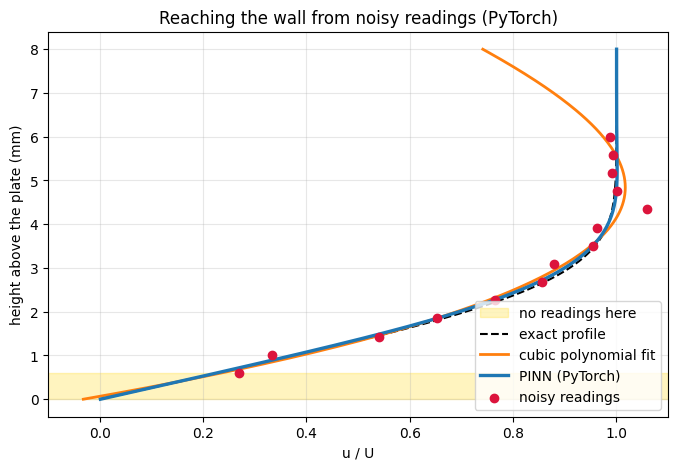

In [ ]:
_, f1_inv, _, wall_inv = profile_and_wall(model_inv)
eta99_inv = boundary_layer_numbers(eta_grid, f1_inv, wall_inv)["eta_99"]

coef_t = np.polyfit(y_meas.ravel(), u_meas.ravel(), 3)
rate_true = U_inf * kappa_true * 1000.0 * wall_slope_exact
rate_pinn = U_inf * kappa_hat_t * 1000.0 * wall_inv
rate_poly = U_inf * coef_t[2] * 1000.0

print(f"{'':34s}{'estimate':>12s}{'truth':>12s}{'error':>10s}")
print(f"{'scale kappa (per mm), PINN':34s}{kappa_hat_t:12.4f}{kappa_true:12.4f}{100*(kappa_hat_t/kappa_true-1):9.1f}%")
print(f"{'wall velocity gradient (1/s), PINN':34s}{rate_pinn:12.0f}{rate_true:12.0f}{100*(rate_pinn/rate_true-1):9.1f}%")
print(f"{'wall velocity gradient (1/s), cubic':34s}{rate_poly:12.0f}{rate_true:12.0f}{100*(rate_poly/rate_true-1):9.1f}%")

y_plot = np.linspace(0, 8, 300)
plt.figure(figsize=(8, 5))
plt.axhspan(0, 0.6, color="gold", alpha=0.25, label="no readings here")
plt.plot(ref(kappa_true * y_plot)[1], y_plot, "k--", label="exact profile")
plt.plot(np.polyval(coef_t, y_plot), y_plot, color="tab:orange", lw=2, label="cubic polynomial fit")
plt.plot(np.interp(kappa_hat_t * y_plot, eta_grid.ravel(), f1_inv), y_plot, color="tab:blue", lw=2.4, label="PINN (PyTorch)")
plt.scatter(u_meas, y_meas, color="crimson", zorder=3, label="noisy readings")
plt.xlim(-0.1, 1.1)
plt.xlabel("u / U")
plt.ylabel("height above the plate (mm)")
plt.title("Reaching the wall from noisy readings (PyTorch)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

Compare with A11. If the two independent implementations land at similar values of $\kappa$ and the wall gradient, that is a useful cross-check. The usual small differences are expected from the different starting weights and the 32-bit arithmetic.

## B12. From the flat plate to wedge flows (Falkner–Skan)
A real surface seldom has zero pressure gradient. If the flow outside the layer speeds up or slows down along the surface as $U_e(x)=Cx^m$, the same similarity method (section 4) works with that outer velocity, and the equation becomes the **Falkner–Skan equation** (Falkner and Skan, 1931; see White, 2006, for the derivation):
$$
f'''+\frac{m+1}{2}\,f\,f''+m\,(1-f'^2)=0,\qquad f(0)=f'(0)=0,\quad f'(\infty)=1 .
$$
* $m=0$ is our Blasius equation.
* $m=1/3$ is the flow over a wedge with a total opening angle of 90 degrees.
* $m=1$ is the flow straight towards a wall, near the **stagnation point** at the nose of a body.

For $m>0$ the outer flow *accelerates*, which squeezes the layer closer to the wall and increases the friction. (For $m>0$, $f\equiv0$ no longer solves the equation, so that nearest useless answer is gone. We did not test whether cold starts are safer there, and the code still uses the warm-up.)

Our `ode_loss` already takes $a=(m+1)/2$ and $m$. The reference comes from SciPy's boundary-value solver `solve_bvp`, and we train one network per value of $m$.

m = 0.000:  wall slope  PINN 0.3320   reference 0.3321   profile RMSE 2.20e-04
m = 0.333:  wall slope  PINN 0.7576   reference 0.7574   profile RMSE 6.85e-05
m = 1.000:  wall slope  PINN 1.2329   reference 1.2326   profile RMSE 6.61e-05


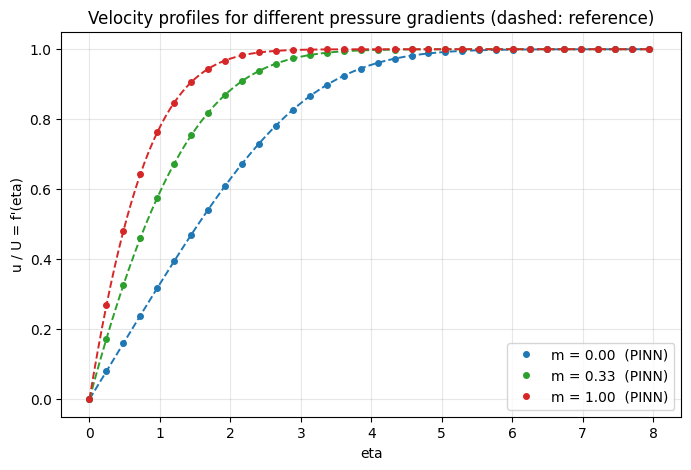

In [ ]:
from scipy.integrate import solve_bvp

def falkner_skan_reference(m_fs):
    a = 0.5 * (m_fs + 1.0)
    def rhs(e, y):
        return np.vstack([y[1], y[2], -a * y[0] * y[2] - m_fs * (1.0 - y[1] ** 2)])
    def bc(ya, yb):
        return np.array([ya[0], ya[1], yb[1] - 1.0])
    e0 = np.linspace(0.0, ETA_MAX, 400)
    y0 = np.vstack([e0 - 1.0 + np.exp(-e0), 1.0 - np.exp(-e0), np.exp(-e0)])
    return solve_bvp(rhs, bc, e0, y0, tol=1e-10, max_nodes=100000)


fs_values = [0.0, 1.0 / 3.0, 1.0]
fs_results = []
for m_fs in fs_values:
    sol = falkner_skan_reference(m_fs)
    model_fs, _, _ = train_torch(seed=0, epochs=6000, warmup_epochs=500, a=0.5 * (m_fs + 1.0), m_fs=m_fs, verbose=False)
    _, f1_fs, _, wall_fs = profile_and_wall(model_fs)
    f1_ref = sol.sol(eta_grid.ravel())[1]
    fs_results.append((m_fs, sol.y[2, 0], wall_fs, rmse(f1_fs, f1_ref), f1_fs, f1_ref))
    print(f"m = {m_fs:.3f}:  wall slope  PINN {wall_fs:.4f}   reference {sol.y[2, 0]:.4f}   profile RMSE {rmse(f1_fs, f1_ref):.2e}")

plt.figure(figsize=(8, 5))
for (m_fs, _, _, _, f1_fs, f1_ref), colour in zip(fs_results, ("tab:blue", "tab:green", "tab:red")):
    plt.plot(eta_grid, f1_ref, "--", color=colour, lw=1.4)
    plt.plot(eta_grid[::12], f1_fs[::12], "o", color=colour, ms=4, label=f"m = {m_fs:.2f}  (PINN)")
plt.xlabel("eta")
plt.ylabel("u / U = f'(eta)")
plt.title("Velocity profiles for different pressure gradients (dashed: reference)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

The profile becomes "fuller" (it rises more steeply near the wall) as $m$ grows, and the wall slope grows with it. That is the engineering meaning of a favourable pressure gradient: more friction, but a layer that holds on to the surface and resists separating. The opposite case, $m<0$ (flow slowing down), thickens the layer and, at about $m=-0.09$, the wall slope reaches zero. That is the point where the flow separates from the surface. It is a good extension to try with this code (the equation still holds, but the reference solution then has more than one branch, so it needs care).

---
# Summary

| | Part A (NumPy) | Part B (PyTorch) |
|---|---|---|
| Three derivatives of the network | Chain rule written out by hand, layer by layer | `torch.autograd.grad` three times, or `torch.func` |
| Gradient of the loss | Derived by hand, tested against finite differences | `loss.backward()` |
| Optimiser | Adam from its equations, decaying step size | `torch.optim.Adam` with `ExponentialLR`, then `LBFGS` |
| Unknown scale in the inverse problem | Gradient derived and coded by hand | `nn.Parameter` and autograd |
| Beyond Blasius | (not covered) | Falkner–Skan flows with the same loss code |
| Good for | Understanding every step | Faster experiments, other optimisers, bigger problems |

**What the experiments showed**

* A PINN can *solve* a third-order boundary-value problem using only the equation and the three boundary conditions. It reproduced the wall slope, the number that sets the drag.
* The solution can be checked without knowing the answer, using the momentum balance (3), the same kind of test as the energy check in the oscillator notebook.
* Random starts matter. A network started from random weights can sink into the useless $f=0$ answer. A short warm-up on a rough guess avoided it in our runs. Looking at one run is not enough, and a survey over several starts is cheap insurance.
* When measurements are available, the physics fills in where they cannot reach. Here it recovered the wall friction from noisy readings that stopped short of the wall.

**Limits of this example**

* The reference solution lets us measure the error directly. In real problems it usually does not exist, so checks such as the residual and the momentum balance matter.
* The survey uses six seeds, and the inverse problem uses one noise sample (plus a repeat test that reuses the solved profile). A careful study would repeat everything more widely.
* We tried one rough warm-up guess and one network size. Two other ideas did not cure the trap by themselves. Giving the far-field condition 10 or 100 times more weight did not rescue a stuck run, which makes sense: in a stuck run that condition is already met (its loss is about $2\times10^{-5}$) and the equation is what is violated. Building the wall conditions into the network by writing $f=\eta^2N(\eta)$ (Section A10b) changed which seeds got stuck but did not remove the trap. With the warm-up, that version solved all three seeds we tried (wall slopes 0.3313, 0.3328 and 0.3325), a little less accurately than the usual network at the same number of epochs. We did not try longer training, other optimisers, or a larger weight on the equation.
* The flat-plate solution only holds for steady, laminar, zero-pressure-gradient flow up to a Reynolds number of about $5\times10^5$.
* For this equation a classical method is faster and more accurate. A PINN is worth it when data and equations have to be combined, when constants are unknown, or when the problem is a PDE.

**Design choices that are ours, not part of the physics**

| Choice | Why |
|---|---|
| $\eta_{\max}=8$ | The profile is within about $10^{-5}$ of the free stream there |
| 200 collocation points | Dense enough to hold the curve over the whole interval |
| 500-epoch warm-up on $1-e^{-\eta/2}$ | Starts the network away from the do-nothing solution |
| Learning rate from $3\times10^{-3}$ to $10^{-4}$ | A fixed rate jitters late in training |
| Equal weights on the equation and the boundary | They worked here; other balances may be better |

**Things to try**

* Change `ETA_MAX` to 6 or 12 and see how the answer moves.
* Use fewer collocation points and watch how far the network can wander between them.
* Make the warm-up guess worse (for example, $f'\approx\eta/8$) and see whether it still helps.
* Move the measurement window (S8) away from the wall, or add more noise, and watch the inverse problem degrade.
* Try $m<0$ in B12 with a good starting profile, and look for the separation point.

# References

1. L. Prandtl, *Über Flüssigkeitsbewegung bei sehr kleiner Reibung*, Verhandlungen des III. Internationalen Mathematiker-Kongresses, Heidelberg, 484–491 (1904).
2. H. Blasius, *Grenzschichten in Flüssigkeiten mit kleiner Reibung*, Zeitschrift für Mathematik und Physik, 56, 1–37 (1908).
3. V. M. Falkner, S. W. Skan, *Some approximate solutions of the boundary layer equations*, Philosophical Magazine, 12, 865–896 (1931).
4. H. Schlichting, K. Gersten, *Boundary-Layer Theory*, 9th edition, Springer (2017).
5. F. M. White, *Viscous Fluid Flow*, 3rd edition, McGraw-Hill (2006).
6. J. D. Anderson, *Fundamentals of Aerodynamics*, 6th edition, McGraw-Hill (2017).
7. M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, Journal of Computational Physics, 378, 686–707 (2019).
8. S. Cuomo, V. S. Di Cola, F. Giampaolo, G. Rozza, M. Raissi, F. Piccialli, *Scientific machine learning through physics-informed neural networks: Where we are and what's next*, Journal of Scientific Computing, 92, 88 (2022).
9. D. P. Kingma, J. Ba, *Adam: A method for stochastic optimization*, ICLR (2015).
10. X. Glorot, Y. Bengio, *Understanding the difficulty of training deep feedforward neural networks*, AISTATS, 249–256 (2010).
11. D. C. Liu, J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Mathematical Programming, 45, 503–528 (1989).
12. A. G. Baydin, B. A. Pearlmutter, A. A. Radul, J. M. Siskind, *Automatic differentiation in machine learning: a survey*, Journal of Machine Learning Research, 18(153), 1–43 (2018).
13. S. Wang, Y. Teng, P. Perdikaris, *Understanding and mitigating gradient flow pathologies in physics-informed neural networks*, SIAM Journal on Scientific Computing, 43(5), A3055–A3081 (2021).
14. A. Krishnapriyan, A. Gholami, S. Zhe, R. Kirby, M. W. Mahoney, *Characterizing possible failure modes in physics-informed neural networks*, Advances in Neural Information Processing Systems 34 (2021).
15. S. Wang, X. Yu, P. Perdikaris, *When and why PINNs fail to train: A neural tangent kernel perspective*, Journal of Computational Physics, 449, 110768 (2022).